# CSC17104 · Đồ án cuối kỳ – Notebook 02: Phân tích 5 câu hỏi (non-ML)

Notebook này dùng dữ liệu đã làm sạch ở notebook 01 (`data/processed/postings_clean.parquet`). Mỗi câu hỏi gồm: **tiền xử lý** (kèm số dòng sau mỗi bước lọc) → **phương pháp** → **kết quả** (≥ 2 biểu đồ, trả lời bằng con số cụ thể) → **hạn chế**.

| # | Câu hỏi | Người phụ trách | Tiêu chí |
|---|---|---|---|
| Q1 | Luật minh bạch lương & tỉ lệ công bố lương | Đinh Võ Thủy Tiên | D1, D3, D4, D5, D6 |
| Q2 | Mức chênh lương của việc remote | Đinh Võ Thủy Tiên | D3, D4, D5, D6 |
| Q3 | Bậc thang lương Entry → Mid-Senior theo nhóm nghề | Huỳnh Huy Hoàng | D1, D2, D3, D5, D6 |
| Q4 | Công ty lớn có trả lương cao hơn? | Huỳnh Huy Hoàng | D1, D3, D4, D5, D6 |
| Q5 | Yếu tố làm người xem nộp đơn nhiều hơn | Hoàng Hùng Quân | D3, D4, D5, D6 |

**Ba công cụ dùng xuyên suốt** (code ở ô thứ hai bên dưới, mỗi hàm chỉ vài dòng NumPy/pandas)
1. **Bootstrap → khoảng tin cậy 95% (D5).** Rút ngẫu nhiên lại các tin *có hoàn lại* (cùng số lượng với mẫu gốc), tính lại con số cần đo, lặp 200–1,000 lần. CI là phân vị 2.5% và 97.5% của các kết quả. Cách này không cần giả định phân phối chuẩn, phù hợp với lương lệch phải.
2. **So sánh trong từng nhóm con (D4)** – hàm `compare_within_groups`. Muốn biết A có khác B "khi các yếu tố khác như nhau" (vd. remote vs. tại chỗ *cùng cấp bậc*), ta chia tin thành các nhóm con có cùng giá trị của biến gây nhiễu, so sánh A với B **trong từng nhóm con**, rồi lấy trung bình có trọng số các chênh lệch (trọng số = số tin ít hơn của hai phía). Chỉ dùng `groupby` + `unstack`.
3. **Kiểm định và effect size (D5)** từ `scipy.stats`: chi-square cho hai tỉ lệ, Mann–Whitney cho lương (không cần phân phối chuẩn), kiểm định dấu (binomial); Cohen's h cho độ lớn chênh lệch giữa hai tỉ lệ.

> **Lưu ý.** Bootstrap ở đây rút lại từng *tin*, tức là coi các tin độc lập với nhau. Thực tế một công ty có thể đăng hàng trăm tin gần giống nhau, nên CI tính theo từng tin có thể **hẹp hơn đáng kể** so với thực tế (có thể vài lần). Vì vậy nhóm chỉ kết luận chắc chắn khi chênh lệch lớn hơn nhiều so với độ rộng CI, và ở Q1–Q4 chạy lại kết luận sau khi **loại bản sao đa địa điểm** (kiểm tra độ vững – D6).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats as sps

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.data import (PROCESSED_DIR, RAW_DIR, TRANSPARENCY_STATES, ON_REQUEST_STATES, LATE_STATES,
                      load_job_functions, cluster_id)
from src.viz import set_style, SERIES, NEUTRAL, TEXT_2, GRID, SEQ_CMAP, GROUP_COLORS, usd, pct, note

set_style()
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

df = pd.read_parquet(PROCESSED_DIR / 'postings_clean.parquet')
df['company'] = cluster_id(df)   # mã công ty: company_id, nếu thiếu thì dùng tên công ty
print(df.shape)

(123849, 46)


In [2]:
# Các hàm thống kê dùng chung cho Q1–Q5 (bootstrap, so sánh trong nhóm con, Cohen's h)

def bootstrap_ci(values, stat=np.mean, n_boot=1000, seed=42):
    """Khoảng tin cậy 95% cho stat(values) bằng percentile bootstrap.

    Lặp n_boot lần: rút ngẫu nhiên len(values) phần tử CÓ HOÀN LẠI, tính stat.
    CI = phân vị 2.5% và 97.5% của n_boot giá trị đó.
    Trả về (giá trị ước lượng, cận dưới, cận trên).
    """
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    boots = [stat(rng.choice(values, size=len(values), replace=True)) for _ in range(n_boot)]
    return stat(values), np.percentile(boots, 2.5), np.percentile(boots, 97.5)


def bootstrap_diff(a, b, stat=np.mean, n_boot=1000, seed=42):
    """CI 95% cho stat(a) − stat(b); hai mẫu được rút lại độc lập với nhau."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    rng = np.random.default_rng(seed)
    boots = [stat(rng.choice(a, len(a))) - stat(rng.choice(b, len(b))) for _ in range(n_boot)]
    return stat(a) - stat(b), np.percentile(boots, 2.5), np.percentile(boots, 97.5)


def bootstrap_ratio(a, b, stat=np.median, n_boot=1000, seed=42):
    """CI 95% cho stat(a) / stat(b), ví dụ median lương nhóm A / median lương nhóm B."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    rng = np.random.default_rng(seed)
    boots = [stat(rng.choice(a, len(a))) / stat(rng.choice(b, len(b))) for _ in range(n_boot)]
    return stat(a) / stat(b), np.percentile(boots, 2.5), np.percentile(boots, 97.5)


def bootstrap_df(df, func, n_boot=200, seed=42):
    """Bootstrap cho một thống kê tính trên cả DataFrame (vd: kết quả của compare_within_groups).

    Mỗi lần lặp rút lại các DÒNG của df có hoàn lại rồi gọi func(df_mới) -> một số.
    Nên truyền vào df chỉ gồm các cột cần dùng để chạy nhanh hơn.
    """
    rng = np.random.default_rng(seed)
    est = func(df)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(df), size=len(df))
        boots.append(func(df.iloc[idx]))
    return est, np.nanpercentile(boots, 2.5), np.nanpercentile(boots, 97.5)


def cohens_h(p1, p2):
    """Độ lớn chênh lệch giữa hai tỉ lệ: |h| ≈ 0.2 nhỏ, 0.5 vừa, 0.8 lớn."""
    return 2 * np.arcsin(np.sqrt(p1)) - 2 * np.arcsin(np.sqrt(p2))


def compare_within_groups(df, by, group_col, value_col, g1, g0, agg="mean", min_n=10, log_ratio=False):
    """So sánh nhóm g1 với nhóm g0 TRONG TỪNG NHÓM CON xác định bởi các cột `by`.

    Ý tưởng: muốn biết remote có trả cao hơn không mà không bị nhiễu bởi cấp bậc, thì
    so sánh remote với tại chỗ TRONG CÙNG cấp bậc, rồi lấy trung bình các chênh lệch.

    Các bước:
    1. groupby(by + [group_col]) → agg(value_col) và số dòng của từng ô.
    2. Chỉ giữ nhóm con có ≥ min_n dòng ở CẢ HAI phía g1 và g0.
    3. Chênh lệch trong từng nhóm con:
       - log_ratio=False: agg(g1) − agg(g0)                  (dùng cho tỉ lệ)
       - log_ratio=True : log(agg(g1) / agg(g0))             (dùng cho lương)
    4. Trung bình có trọng số các chênh lệch, trọng số = số dòng ít hơn của hai phía
       (nhóm con có ít dữ liệu ở một phía thì kém tin cậy hơn).
       Với log_ratio=True, kết quả được đổi lại thành % chênh lệch: exp(trung bình) − 1.

    `by` rỗng ([]) nghĩa là không kiểm soát gì (so sánh thô).
    Trả về (chênh lệch trung bình, bảng chi tiết từng nhóm con).
    """
    by = [by] if isinstance(by, str) else list(by)
    if not by:
        df = df.assign(_tat_ca="tất cả")
        by = ["_tat_ca"]
    keys = by + [group_col]
    stat = df.groupby(keys, observed=True)[value_col].agg(agg).unstack(group_col)
    size = df.groupby(keys, observed=True)[value_col].size().unstack(group_col)
    if g1 not in size.columns or g0 not in size.columns:
        return np.nan, pd.DataFrame()

    ok = (size[g1] >= min_n) & (size[g0] >= min_n)
    table = pd.DataFrame({"gia_tri_1": stat.loc[ok, g1], "gia_tri_0": stat.loc[ok, g0],
                          "n_1": size.loc[ok, g1], "n_0": size.loc[ok, g0]})
    if table.empty:
        return np.nan, table
    if log_ratio:
        table["chenh_lech"] = np.log(table["gia_tri_1"] / table["gia_tri_0"])
    else:
        table["chenh_lech"] = table["gia_tri_1"] - table["gia_tri_0"]
    table["trong_so"] = np.minimum(table["n_1"], table["n_0"])

    est = np.average(table["chenh_lech"], weights=table["trong_so"])
    if log_ratio:
        est = np.exp(est) - 1
    return est, table

In [3]:
def row_report(steps):
    """In bảng số dòng sau mỗi bước lọc."""
    out = pd.DataFrame(steps, columns=['bước', 'số dòng'])
    out['thay đổi'] = out['số dòng'].diff().fillna(0).astype(int)
    return out

def ci_text(est, lo, hi, kind='pp'):
    """Viết 'ước lượng (95% CI thấp … cao)' – kind='pp' cho điểm %, kind='%' cho % chênh lệch."""
    if kind == 'pp':
        return f'{est*100:+.1f} điểm % (95% CI {lo*100:+.1f} … {hi*100:+.1f})'
    return f'{est:+.1%} (95% CI {lo:+.1%} … {hi:+.1%})'

---
## Q1 – Luật minh bạch lương có làm nhà tuyển dụng công bố lương nhiều hơn không?
*Người phụ trách: Đinh Võ Thủy Tiên (24120148)*

**Câu hỏi.** Các bang bắt buộc ghi khoảng lương trong tin tuyển dụng (CA, CO, WA, NY, HI) có tỉ lệ tin công bố lương cao hơn bao nhiêu điểm phần trăm (pp) so với các bang không có luật, khi so sánh **trong cùng một công ty**, cùng nhóm chức năng và quy mô? Các bang chỉ yêu cầu cung cấp lương "khi ứng viên hỏi" (CT, NV, RI, MD) có khác các bang không có luật không?

**Động lực.** Nhiều bang khác (IL, MN, MA, NJ, VT…) đã ban hành luật tương tự có hiệu lực từ 2025. Nhà làm chính sách muốn biết luật có thực sự thay đổi cách doanh nghiệp đăng tin tuyển dụng hay không. Người tìm việc muốn biết nên tìm việc ở đâu nếu muốn biết lương trước khi nộp đơn.

**Bối cảnh pháp lý (thời điểm dữ liệu: 04/2024).** Các nơi bắt buộc ghi lương trong tin: Colorado (từ 01/2021), California và Washington (01/2023), New York City (11/2022) và toàn bang New York (17/09/2023), Hawaii (01/2024, chỉ áp dụng cho công ty ≥ 50 nhân viên). Connecticut, Nevada, Rhode Island và Maryland *trước 10/2024* chỉ yêu cầu cung cấp khi ứng viên hỏi. DC, Illinois, Minnesota có luật **sau** thời điểm dữ liệu → xếp vào nhóm "không có luật" (kiểm tra lại ở robustness). *Nguồn: tổng hợp luật minh bạch lương theo bang của Seyfarth Shaw, NBC News và các trang tổng hợp luật theo bang, liệt kê trong README.*

**Hướng tiếp cận.** Nhóm đi từ đơn giản đến chặt chẽ: (1) so sánh thô tỉ lệ ghi lương giữa ba nhóm bang; (2) so sánh trong cùng một công ty để loại khác biệt giữa các công ty; (3) so sánh trong cùng nhóm chức năng, quy mô công ty và cấp bậc; (4) thay đổi các lựa chọn xử lý dữ liệu để xem kết luận có đổi không.

### Tiền xử lý
1. Bỏ tin tuyển **toàn quốc** (địa điểm ghi "United States") và tin **không xác định được bang**, vì không biết được luật áp dụng.
2. Tạo hai biến mới (D3): `law_group` chia bang thành ba nhóm (Có luật công khai lương / Chỉ khi được hỏi / Không có luật); `disclosed` bằng 1 nếu tin có điền trường lương. Vì ở đây nhóm đo *hành vi ghi lương*, nên vẫn tính cả những tin có ghi lương nhưng giá trị bị loại ở bước làm sạch.
3. Thông tin quy mô công ty (`employee_bucket`) và chức năng đến từ các bảng đã ghép ở notebook 01 (D1).

In [4]:
steps = [('Bảng đã làm sạch', len(df))]
q1 = df[~df['is_nationwide']]
steps.append(('Bỏ tin tuyển toàn quốc ("United States")', len(q1)))
q1 = q1[q1['state'].notna()].copy()
steps.append(('Bỏ tin không xác định được bang', len(q1)))
display(row_report(steps))

q1['law_group'] = np.select([q1['state'].isin(TRANSPARENCY_STATES), q1['state'].isin(ON_REQUEST_STATES)],
                            ['Có luật công khai lương', 'Chỉ khi được hỏi'], 'Không có luật')
q1['disclosed'] = q1['salary_disclosed'].astype(float)
print(q1['law_group'].value_counts().to_string())

,bước,số dòng,thay đổi
0,Bảng đã làm sạch,123849,0
1,"Bỏ tin tuyển toàn quốc (""United States"")",115724,-8125
2,Bỏ tin không xác định được bang,114612,-1112


law_group
Không có luật              83689
Có luật công khai lương    26352
Chỉ khi được hỏi            4571


### Phân tích 1 – So sánh thô giữa ba nhóm bang (D5)
- Tỉ lệ tin có ghi lương của từng nhóm bang, kèm CI 95% bằng bootstrap.
- Chênh lệch so với nhóm *Không có luật*, kèm CI bootstrap.
- **Kiểm định chi-square** (H0: tỉ lệ công bố lương ở hai nhóm như nhau) và **Cohen's h** – độ lớn chênh lệch (0.2 nhỏ, 0.5 vừa, 0.8 lớn). p-value rất nhỏ chỉ nói chênh lệch *không phải do ngẫu nhiên*; Cohen's h mới cho biết chênh lệch *lớn hay nhỏ*.

In [5]:
LAW, ASK, NONE = 'Có luật công khai lương', 'Chỉ khi được hỏi', 'Không có luật'
GROUPS = [LAW, ASK, NONE]
rows = []
for g in GROUPS:
    y = q1.loc[q1['law_group'] == g, 'disclosed']
    est, lo, hi = bootstrap_ci(y, stat=np.mean)
    rows.append({'nhóm bang': g, 'số tin': len(y), 'tỉ lệ có lương': est, 'CI thấp': lo, 'CI cao': hi})
rates = pd.DataFrame(rows).set_index('nhóm bang')
display(rates.style.format({'số tin': '{:,}', 'tỉ lệ có lương': '{:.1%}', 'CI thấp': '{:.1%}', 'CI cao': '{:.1%}'}))

y_none = q1.loc[q1['law_group'] == NONE, 'disclosed']
for g in [LAW, ASK]:
    y = q1.loc[q1['law_group'] == g, 'disclosed']
    d, lo, hi = bootstrap_diff(y, y_none)
    sub = q1[q1['law_group'].isin([g, NONE])]
    chi2, p, dof, _ = sps.chi2_contingency(pd.crosstab(sub['law_group'], sub['disclosed']))
    h = cohens_h(y.mean(), y_none.mean())
    print(f'{g} − {NONE}: {ci_text(d, lo, hi)} | chi-square p = {p:.1e} | Cohen h = {h:.2f}')

,số tin,tỉ lệ có lương,CI thấp,CI cao
nhóm bang,,,,
Có luật công khai lương,"26,352",49.7%,49.1%,50.3%
Chỉ khi được hỏi,"4,571",26.9%,25.6%,28.1%
Không có luật,"83,689",22.5%,22.3%,22.8%


Có luật công khai lương − Không có luật: +27.2 điểm % (95% CI +26.5 … +27.8) | chi-square p = 0.0e+00 | Cohen h = 0.58


Chỉ khi được hỏi − Không có luật: +4.3 điểm % (95% CI +2.9 … +5.6) | chi-square p = 1.3e-11 | Cohen h = 0.10


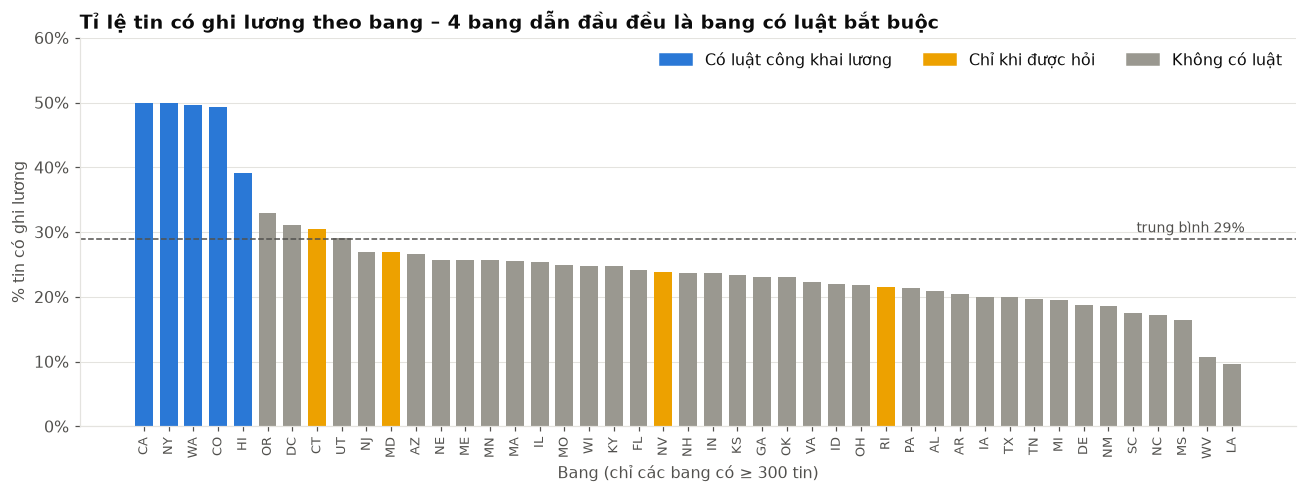

Thứ hạng của các bang có luật: {'CO': 4, 'CA': 1, 'WA': 3, 'NY': 2, 'HI': 5}


In [6]:
by_state = (q1.groupby('state').agg(rate=('disclosed', 'mean'), n=('disclosed', 'size'), group=('law_group', 'first'))
              .query('n >= 300').sort_values('rate', ascending=False))
fig, ax = plt.subplots(figsize=(12, 4.6))
colors = [GROUP_COLORS[g] for g in by_state['group']]
ax.bar(by_state.index, by_state['rate'], color=colors, width=0.72)
ax.axhline(q1['disclosed'].mean(), color=TEXT_2, linestyle='--', linewidth=1)
ax.text(len(by_state) - 0.5, q1['disclosed'].mean() + 0.01, f"trung bình {q1['disclosed'].mean():.0%}", ha='right', color=TEXT_2, fontsize=9)
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, 0.6)
ax.set_title('Tỉ lệ tin có ghi lương theo bang – 4 bang dẫn đầu đều là bang có luật bắt buộc')
ax.set_xlabel('Bang (chỉ các bang có ≥ 300 tin)'); ax.set_ylabel('% tin có ghi lương')
ax.tick_params(axis='x', labelsize=8.5, rotation=90); ax.grid(axis='x', visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLORS[g]) for g in ['Có luật công khai lương', 'Chỉ khi được hỏi', 'Không có luật']]
ax.legend(handles, ['Có luật công khai lương', 'Chỉ khi được hỏi', 'Không có luật'], loc='upper right', ncol=3)
plt.tight_layout(); plt.show()
print('Thứ hạng của các bang có luật:', {s: int(np.where(by_state.index == s)[0][0]) + 1 for s in TRANSPARENCY_STATES if s in by_state.index})

### Phân tích 2 – So sánh trong cùng một công ty (D4)
Chênh lệch thô có thể đến từ việc mỗi bang có tập công ty khác nhau. Ví dụ, California có nhiều công ty công nghệ, vốn hay ghi lương dù có luật hay không. Để loại yếu tố này, nhóm chỉ giữ những công ty đăng tin ở cả bang có luật lẫn bang không có luật:
1. Với mỗi công ty, tính tỉ lệ ghi lương ở bang có luật và ở bang không có luật (`groupby(['company', 'law_group'])` rồi `unstack`).
2. Lấy hiệu của hai tỉ lệ đó, mỗi công ty có một con số.
3. Lấy trung bình các hiệu (trọng số = số tin ít hơn của hai phía). Nếu luật không có tác dụng thì trung bình này sẽ dao động quanh 0.

Nhóm dùng thêm kiểm định dấu (sign test): trong các công ty có hiệu khác 0, tỉ lệ công ty có hiệu dương có khác 50% hay không (`scipy.stats.binomtest`).

In [7]:
cmp = q1.loc[q1['law_group'] != ASK, ['company', 'law_group', 'disclosed', 'job_function',
                                      'employee_bucket', 'experience_level']]

def law_within(d, by, min_n=1):
    """Chênh lệch tỉ lệ công bố (có luật − không luật) trong từng nhóm con `by`."""
    return compare_within_groups(d, by, 'law_group', 'disclosed', LAW, NONE, min_n=min_n)

d_comp, by_comp = law_within(cmp, ['company'])
print(f'Số công ty đăng tin ở cả hai nhóm bang: {len(by_comp):,} '
      f'(chiếm {(by_comp["n_1"] + by_comp["n_0"]).sum() / len(cmp):.0%} số tin của hai nhóm)')
est_c, lo_c, hi_c = bootstrap_df(cmp[['company', 'law_group', 'disclosed']],
                                 lambda d: law_within(d, ['company'])[0], n_boot=200)
print(f'Chênh lệch trung bình trong cùng công ty: {ci_text(est_c, lo_c, hi_c)}')

pos, neg = (by_comp['chenh_lech'] > 0).sum(), (by_comp['chenh_lech'] < 0).sum()
bt = sps.binomtest(pos, pos + neg, 0.5)
print(f'Công ty công bố nhiều hơn ở bang có luật: {pos:,} | ít hơn: {neg:,} | bằng nhau: {(by_comp["chenh_lech"] == 0).sum():,}')
print(f'Kiểm định dấu: {pos / (pos + neg):.1%} công ty có hiệu dương, p = {bt.pvalue:.1e}')

Số công ty đăng tin ở cả hai nhóm bang: 3,212 (chiếm 59% số tin của hai nhóm)

Chênh lệch trung bình trong cùng công ty: +17.5 điểm % (95% CI +16.9 … +18.5)
Công ty công bố nhiều hơn ở bang có luật: 1,396 | ít hơn: 621 | bằng nhau: 1,195
Kiểm định dấu: 69.2% công ty có hiệu dương, p = 3.0e-68


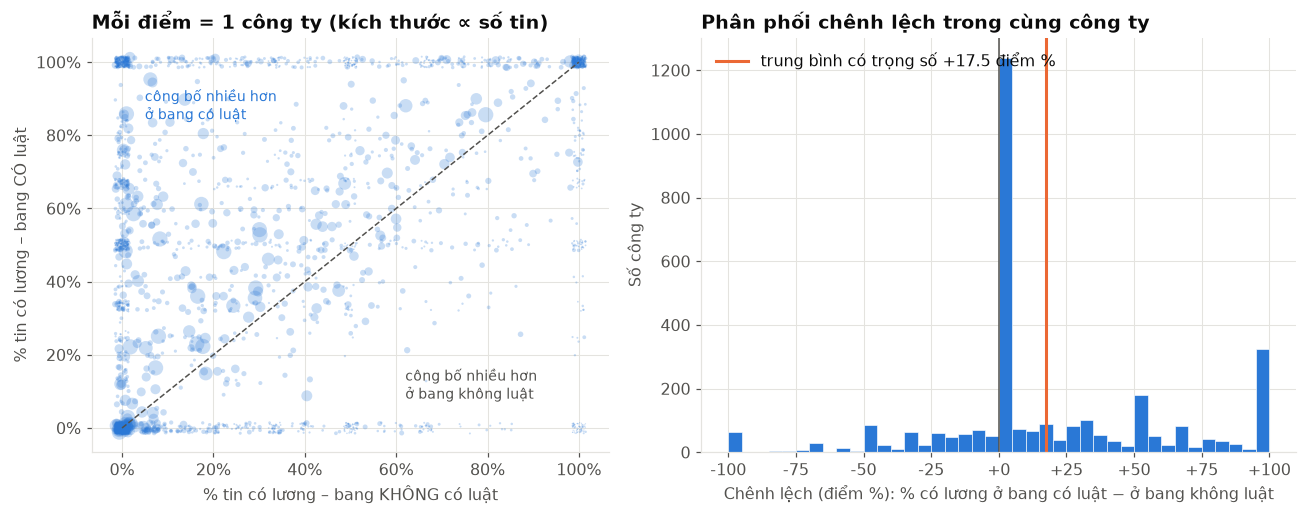

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={'width_ratios': [1, 1.15]})
ax = axes[0]
sz = np.clip(by_comp['n_1'] + by_comp['n_0'], 2, 300)
rng = np.random.default_rng(0)
jit = lambda s: s + rng.uniform(-0.015, 0.015, len(s))
ax.scatter(jit(by_comp['gia_tri_0']), jit(by_comp['gia_tri_1']), s=sz / 3, alpha=0.25, color=SERIES[0], edgecolor='none')
ax.plot([0, 1], [0, 1], color=TEXT_2, linestyle='--', linewidth=1)
ax.text(0.05, 0.93, 'công bố nhiều hơn\nở bang có luật', color=SERIES[0], fontsize=9, va='top')
ax.text(0.62, 0.08, 'công bố nhiều hơn\nở bang không luật', color=TEXT_2, fontsize=9)
ax.set_xlabel('% tin có lương – bang KHÔNG có luật'); ax.set_ylabel('% tin có lương – bang CÓ luật')
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set_title('Mỗi điểm = 1 công ty (kích thước ∝ số tin)')
ax = axes[1]
ax.hist(by_comp['chenh_lech'], bins=np.linspace(-1, 1, 41), color=SERIES[0], edgecolor='white', linewidth=0.4)
ax.axvline(0, color=TEXT_2, linewidth=1)
ax.axvline(est_c, color=SERIES[1], linewidth=2, label=f'trung bình có trọng số {est_c*100:+.1f} điểm %')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v*100:+.0f}'))
ax.set_xlabel('Chênh lệch (điểm %): % có lương ở bang có luật − ở bang không luật')
ax.set_ylabel('Số công ty'); ax.legend(loc='upper left')
ax.set_title('Phân phối chênh lệch trong cùng công ty')
plt.tight_layout(); plt.show()

### Phân tích 3 – Thêm dần biến kiểm soát: chức năng, quy mô, cấp bậc (D4)
Ngoài công ty, bang có luật có thể có nhiều việc thuộc *nhóm chức năng* hay *quy mô công ty* vốn hay công bố lương. Ta so sánh bang có luật với bang không luật **trong từng nhóm con**, thêm dần biến: cùng chức năng → cùng chức năng × quy mô công ty → cùng chức năng × quy mô × cấp bậc. Chỉ giữ nhóm con có ≥ 20 tin ở mỗi phía (với "cùng công ty": ≥ 1 tin mỗi phía như Phân tích 2). Nếu chênh lệch gần như không đổi thì các biến này không giải thích được khoảng cách giữa hai nhóm bang. CI: bootstrap 200 lần.

In [9]:
specs1 = {
    'Thô (không kiểm soát)': [],
    'Cùng chức năng': ['job_function'],
    'Cùng chức năng × quy mô': ['job_function', 'employee_bucket'],
    'Cùng chức năng × quy mô × cấp bậc': ['job_function', 'employee_bucket', 'experience_level'],
    'Cùng công ty': ['company'],
}
rows = []
for name, by in specs1.items():
    min_n = 1 if by == ['company'] else 20
    cols = ['law_group', 'disclosed'] + by
    est, lo, hi = bootstrap_df(cmp[cols], lambda d: law_within(d, by, min_n)[0], n_boot=200)
    tab = law_within(cmp, by, min_n)[1]
    rows.append({'cách so sánh': name, 'chênh lệch': est, 'lo': lo, 'hi': hi,
                 'số nhóm con': len(tab), '% tin được dùng': (tab['n_1'] + tab['n_0']).sum() / len(cmp)})
ctrl1 = pd.DataFrame(rows).set_index('cách so sánh')
ctrl1.style.format({'chênh lệch': '{:+.1%}', 'lo': '{:+.1%}', 'hi': '{:+.1%}', 'số nhóm con': '{:,}', '% tin được dùng': '{:.0%}'})

,chênh lệch,lo,hi,số nhóm con,% tin được dùng
cách so sánh,,,,,
Thô (không kiểm soát),+27.2%,+26.5%,+27.8%,1,100%
Cùng chức năng,+26.5%,+25.8%,+27.1%,36,100%
Cùng chức năng × quy mô,+26.3%,+25.6%,+27.0%,130,97%
Cùng chức năng × quy mô × cấp bậc,+25.5%,+24.7%,+26.1%,277,85%
Cùng công ty,+17.5%,+16.9%,+18.5%,"3,212",59%


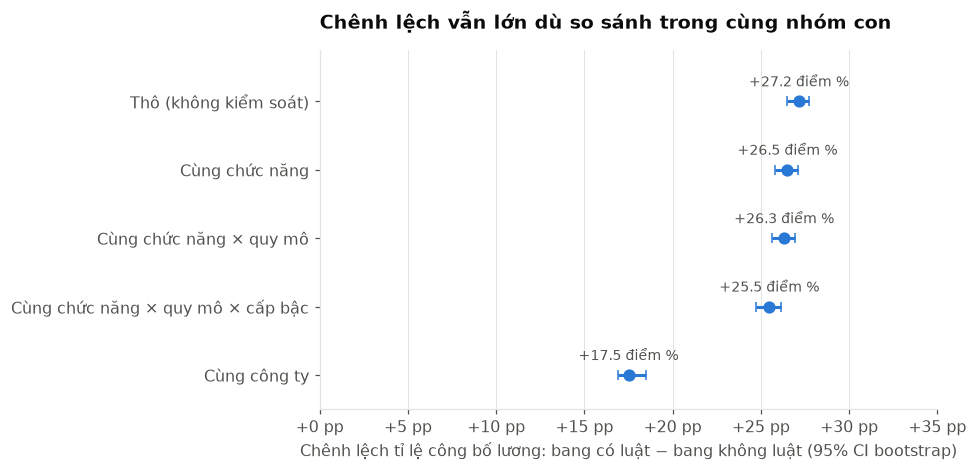

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.4))
y = np.arange(len(ctrl1))
ax.errorbar(ctrl1['chênh lệch'], y, xerr=[ctrl1['chênh lệch'] - ctrl1['lo'], ctrl1['hi'] - ctrl1['chênh lệch']],
            fmt='o', color=SERIES[0], capsize=3)
for yi, v in zip(y, ctrl1['chênh lệch']):
    ax.text(v, yi - 0.22, f'{v*100:+.1f} điểm %', ha='center', fontsize=9, color=TEXT_2)
ax.axvline(0, color=TEXT_2, linewidth=1)
ax.set_yticks(y); ax.set_yticklabels(ctrl1.index); ax.invert_yaxis()
ax.set_ylim(len(ctrl1) - 0.5, -0.75)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:+.0f} pp'))
ax.set_xlim(0, 0.35)
ax.set_xlabel('Chênh lệch tỉ lệ công bố lương: bang có luật − bang không luật (95% CI bootstrap)')
ax.set_title('Chênh lệch vẫn lớn dù so sánh trong cùng nhóm con', pad=14)
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

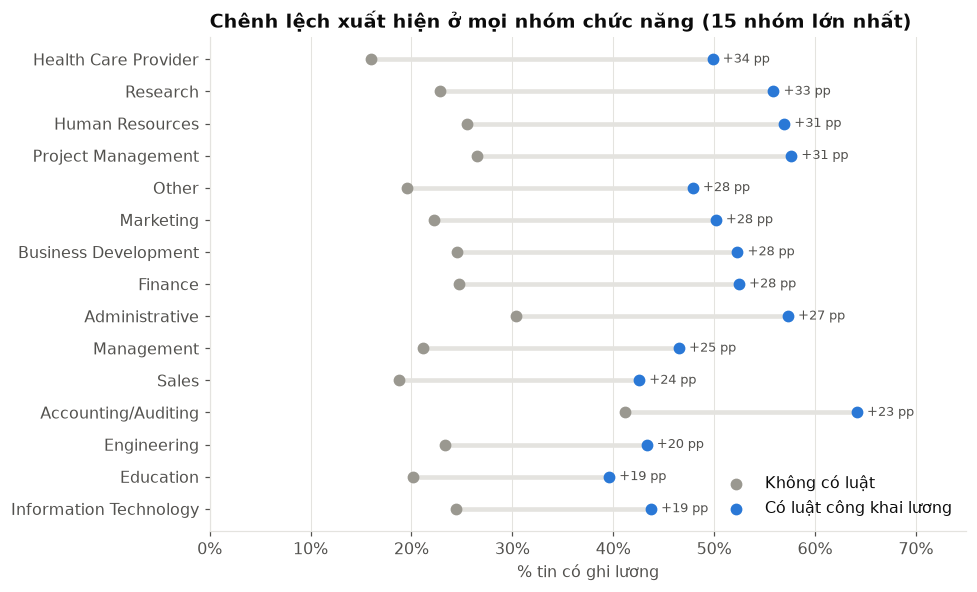

Nhỏ nhất: Information Technology +19 pp | lớn nhất: Health Care Provider +34 pp


In [11]:
# Hiệu ứng có đồng đều giữa các nhóm chức năng? (top 15 chức năng nhiều tin nhất)
top_f = q1['job_function'].value_counts().index[:15]
pv = (q1[q1['job_function'].isin(top_f) & (q1['law_group'] != 'Chỉ khi được hỏi')]
        .pivot_table(index='job_function', columns='law_group', values='disclosed', aggfunc='mean'))
pv['diff'] = pv['Có luật công khai lương'] - pv['Không có luật']
pv = pv.sort_values('diff')
fig, ax = plt.subplots(figsize=(9, 5.5))
y = np.arange(len(pv))
ax.hlines(y, pv['Không có luật'], pv['Có luật công khai lương'], color=GRID, linewidth=3)
ax.scatter(pv['Không có luật'], y, color=NEUTRAL, s=45, zorder=3, label='Không có luật')
ax.scatter(pv['Có luật công khai lương'], y, color=SERIES[0], s=45, zorder=3, label='Có luật công khai lương')
for yi, (a, b) in enumerate(zip(pv['Không có luật'], pv['Có luật công khai lương'])):
    ax.text(b + 0.01, yi, f'+{(b-a)*100:.0f} pp', va='center', fontsize=8.5, color=TEXT_2)
ax.set_yticks(y); ax.set_yticklabels(pv.index)
ax.xaxis.set_major_formatter(pct); ax.set_xlim(0, 0.75)
ax.set_xlabel('% tin có ghi lương'); ax.legend(loc='lower right')
ax.set_title('Chênh lệch xuất hiện ở mọi nhóm chức năng (15 nhóm lớn nhất)')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()
print(f"Nhỏ nhất: {pv['diff'].idxmin()} {pv['diff'].min()*100:+.0f} pp | lớn nhất: {pv['diff'].idxmax()} {pv['diff'].max()*100:+.0f} pp")

### Phân tích 4 – Kiểm tra độ vững (D6)
Kết luận có đổi khi thay đổi những lựa chọn hợp lý sau không? (chênh lệch thô có luật − không luật, CI bootstrap 500 lần)
- **(a)** Bỏ HI (luật chỉ áp dụng công ty ≥ 50 nhân viên) và NY (luật toàn bang mới có hiệu lực 7 tháng).
- **(b)** Bỏ DC, IL, MN khỏi nhóm "không có luật" (đã thông qua luật nhưng chưa có hiệu lực – nhà tuyển dụng có thể đã chuẩn bị trước).
- **(c)** Loại bản sao đa địa điểm: giữ 1 tin cho mỗi (công ty, tiêu đề, bang).
- **(d)** Chỉ xét Full-time.
- **(e)** Thước đo khác: tin có lương **hợp lệ** (sau làm sạch) thay vì có ghi lương.

In [12]:
def law_gap(d, y='disclosed'):
    """Chênh lệch tỉ lệ (có luật − không luật) kèm CI bootstrap."""
    return bootstrap_diff(d.loc[d['law_group'] == LAW, y], d.loc[d['law_group'] == NONE, y], n_boot=500)

alts1 = {
    'Gốc': q1,
    '(a) Bỏ HI và NY': q1[~q1['state'].isin(['HI', 'NY'])],
    '(b) Bỏ DC, IL, MN': q1[~q1['state'].isin(LATE_STATES)],
    '(c) Loại bản sao đa địa điểm': q1.drop_duplicates(['company_name', 'title', 'state']),
    '(d) Chỉ Full-time': q1[q1['work_type'] == 'Full-time'],
}
rob1 = pd.DataFrame({k: law_gap(d) for k, d in alts1.items()}, index=['chênh lệch', 'lo', 'hi']).T
rob1['n'] = [len(d) for d in alts1.values()]
q1['valid'] = q1['annual_salary'].notna().astype(float)
rob1.loc['(e) Lương hợp lệ thay vì có ghi'] = [*law_gap(q1, 'valid'), len(q1)]
rob1.style.format({'chênh lệch': '{:+.1%}', 'lo': '{:+.1%}', 'hi': '{:+.1%}', 'n': '{:,.0f}'})

,chênh lệch,lo,hi,n
Gốc,+27.2%,+26.5%,+27.8%,"114,612"
(a) Bỏ HI và NY,+27.3%,+26.5%,+28.1%,"106,556"
"(b) Bỏ DC, IL, MN",+27.5%,+26.9%,+28.2%,"106,701"
(c) Loại bản sao đa địa điểm,+27.1%,+26.4%,+27.9%,"100,112"
(d) Chỉ Full-time,+29.2%,+28.5%,+29.9%,"92,262"
(e) Lương hợp lệ thay vì có ghi,+27.1%,+26.4%,+27.7%,"114,612"


**Kiểm tra thêm – lương ghi trong phần mô tả (D1: ghép lại cột `description` từ file gốc).** Thước đo chính là trường lương *có cấu trúc* của LinkedIn. Một số nhà tuyển dụng tuân thủ luật bằng cách ghi khoảng lương **trong đoạn mô tả** mà không điền trường này. Ta coi tin là "có công bố lương" nếu có trường lương **hoặc** mô tả chứa một số tiền dạng `$<số>`. Đây là thước đo rộng hơn, có thể đếm nhầm các số tiền không phải lương (vd. "thưởng ký hợp đồng $5,000").

In [13]:
desc = pd.read_csv(RAW_DIR / 'postings.csv', usecols=['job_id', 'description'])
desc['money_in_desc'] = desc['description'].str.contains(r'\$\s?\d', regex=True, na=False)
n_before = len(q1)
q1 = q1.merge(desc[['job_id', 'money_in_desc']], on='job_id', how='left', validate='1:1')
print(f'Số dòng trước/sau khi ghép: {n_before:,} → {len(q1):,}; tin không tìm thấy mô tả: {q1["money_in_desc"].isna().sum()}')
q1['disclosed_any'] = (q1['salary_disclosed'] | q1['money_in_desc']).astype(float)
display(q1.groupby('law_group')['disclosed_any'].mean().loc[GROUPS]
          .to_frame('% tin có lương (trường lương hoặc mô tả)').style.format('{:.1%}'))
d_any = law_gap(q1, 'disclosed_any')
print(f'Chênh lệch (thước đo rộng): {ci_text(*d_any)}')
law_only = q1[q1['law_group'] == LAW]
print(f"Ở bang có luật: {(~law_only['salary_disclosed'] & law_only['money_in_desc']).mean():.1%} tin chỉ ghi lương trong mô tả; "
      f"{(1 - law_only['disclosed_any']).mean():.1%} tin không có dấu hiệu lương nào")

Số dòng trước/sau khi ghép: 114,612 → 114,612; tin không tìm thấy mô tả: 0


,% tin có lương (trường lương hoặc mô tả)
law_group,
Có luật công khai lương,72.7%
Chỉ khi được hỏi,41.8%
Không có luật,40.1%


Chênh lệch (thước đo rộng): +32.6 điểm % (95% CI +31.9 … +33.2)
Ở bang có luật: 23.0% tin chỉ ghi lương trong mô tả; 27.3% tin không có dấu hiệu lương nào


**Độ rộng khoảng lương.** Với các tin ghi *khoảng* lương (min–max), độ rộng tương đối = (max − min) / điểm giữa. Con số này cho biết một khoảng lương công bố thường "rộng" bao nhiêu – notebook 03 dùng nó làm mốc cho sai số chấp nhận được của mô hình dự đoán lương.

In [14]:
rng_ = q1[q1['annual_min'].notna() & q1['annual_max'].notna() & (q1['annual_max'] >= q1['annual_min'])].copy()
rng_['width'] = (rng_['annual_max'] - rng_['annual_min']) / rng_['annual_salary']
print(f'Số tin có khoảng lương: {len(rng_):,} | median độ rộng: {rng_["width"].median():.1%}')
print(rng_.groupby('law_group')['width'].median().loc[GROUPS].map('{:.1%}'.format).to_string())

Số tin có khoảng lương: 27,238 | median độ rộng: 22.4%


law_group
Có luật công khai lương    24.4%
Chỉ khi được hỏi           22.2%
Không có luật              22.2%


### Kết luận Q1

**Trả lời: Có, và mức chênh khá lớn.** Ở 5 bang bắt buộc ghi lương, **49.7%** tin có ghi lương (95% CI 49.1–50.3%), gần gấp đôi mức **22.5%** (22.3–22.8%) ở các bang không có luật. Chênh lệch là **+27.2 điểm %** (CI +26.5 … +27.8), Cohen's h = 0.58 (mức trung bình–lớn); kiểm định chi-square cho p ≈ 0 (nhỏ hơn mức máy tính biểu diễn được). Bốn bang có luật lâu nhất (CA, NY, WA, CO) đứng 4 vị trí đầu trong mọi bang, và Hawaii (luật mới nhất, chỉ áp dụng công ty ≥ 50 nhân viên) đứng thứ 5.

**Chênh lệch không đến từ việc "các bang đó có những công ty thích công khai lương":**
- **Trong cùng một công ty** (3,212 công ty đăng tin ở cả hai nhóm bang, chiếm 59% số tin), tỉ lệ công bố ở bang có luật cao hơn **+17.5 điểm %** (CI +16.9 … +18.5). 69% công ty có chênh lệch dương (sign test p ≈ 3·10⁻⁶⁸). Con số này nhỏ hơn mức thô, nghĩa là *một phần* khoảng cách thô đến từ khác biệt giữa các công ty, nhưng phần lớn vẫn còn.
- **Trong cùng nhóm chức năng × quy mô công ty × cấp bậc:** **+25.5 điểm %** (CI +24.7 … +26.1) – gần như không đổi so với mức thô.
- Hiệu ứng có ở **mọi** nhóm chức năng: thấp nhất +19 điểm % (IT), cao nhất +34 điểm % (Health Care Provider).

**Điều quyết định là yêu cầu ghi lương *trong tin*:** các bang chỉ yêu cầu cung cấp lương *khi ứng viên hỏi* (CT, NV, RI, MD) chỉ cao hơn bang không luật **+4.3 điểm %** (CI +2.9 … +5.6, h = 0.10 – rất nhỏ).

**Độ vững (D6):** chênh lệch nằm trong khoảng **+27.1 đến +29.2 điểm %** dù bỏ HI/NY, bỏ các bang sắp có luật, loại bản sao, chỉ xét Full-time hay đổi thước đo. Nếu tính cả lương ghi trong phần mô tả, khoảng cách còn lớn hơn: 72.7% so với 40.1% (+32.6 điểm %).

**Ý nghĩa thực tế.** Người tìm việc ở CA/NY/WA/CO thấy lương ở khoảng một nửa số tin; ở phần lớn các bang khác là khoảng một phần tư. Với nhà làm chính sách, luật bắt buộc ghi lương trong tin gần như **nhân đôi** tỉ lệ công bố, còn luật "khi được hỏi" gần như không tác dụng. Ngay ở bang có luật, **một nửa số tin vẫn không điền trường lương**. Khoảng 23% trong số đó ghi lương trong mô tả, nhưng **27% tin không có bất kỳ con số lương nào**. Lý do có thể là các ngoại lệ của luật (công ty nhỏ, tin do bên thứ ba đăng) hoặc vi phạm. Khoảng lương ở bang có luật rộng hơn một chút (median độ rộng 24.4% so với 22.2% điểm giữa) – dấu hiệu nhẹ của việc tuân thủ "cho có" bằng khoảng lương rộng, nhưng mức chênh nhỏ.

**Hạn chế.** (1) Đây là dữ liệu trong 2 tuần: không có số liệu *trước* khi luật có hiệu lực, nên không thể làm so sánh trước–sau (difference-in-differences). So sánh trong cùng công ty loại được yếu tố *công ty* nhưng chưa loại được yếu tố *bang* (chuẩn mực tuyển dụng địa phương, chi phí sinh hoạt). (2) Bỏ tin tuyển toàn quốc, trong khi luật CA/CO/NY có thể áp dụng cả cho vị trí remote. (3) Bootstrap theo từng tin coi các tin là độc lập; vì một công ty đăng nhiều tin gần giống nhau, CI thật có thể rộng hơn vài lần. Dù vậy chênh lệch +27 điểm % vẫn lớn hơn rất nhiều so với độ rộng đó, nên kết luận không đổi. (4) "Có ghi lương" dựa trên trường dữ liệu của LinkedIn; thước đo dựa trên mô tả có thể đếm nhầm các số tiền không phải lương.

---
## Q2 – Làm remote có được trả lương cao hơn không?
*Người phụ trách: Đinh Võ Thủy Tiên (24120148)*

**Câu hỏi.** Tin cho phép remote có lương công bố cao hơn tin tại chỗ bao nhiêu %, và chênh lệch đó **còn lại bao nhiêu** khi so sánh công việc tương đương – cùng cấp bậc, cùng nhóm chức năng, cùng đơn vị trả lương (giờ/năm) – và khi so sánh trong cùng một công ty?

**Động lực.** Người tìm việc thường nghe hai ý trái ngược nhau: "làm remote thì bị trả thấp hơn" và "việc remote lương cao hơn". Nhà tuyển dụng cũng cần biết mức lương cạnh tranh khi mở vị trí remote. Cái khó là việc remote thường tập trung ở vị trí IT và cấp cao, vốn đã có lương cao. Vì vậy trọng tâm của câu hỏi là tách phần chênh lệch do bản thân việc được làm remote khỏi phần do *loại công việc*.

**Hướng tiếp cận.** (1) Đo chênh lệch thô; (2) xem tin remote và tin tại chỗ khác nhau thế nào về loại công việc; (3) so sánh trong từng nhóm con, thêm dần biến kiểm soát (cấp bậc, chức năng, đơn vị lương); (4) kiểm tra độ vững, gồm cả so sánh trong cùng một công ty.

### Tiền xử lý
1. Chỉ giữ tin có **lương năm hợp lệ** (sau sửa đơn vị và lọc khoảng [$15,080; $1,000,000] ở notebook 01).
2. Biến dẫn xuất (D3): `remote_label` ∈ {Remote, Tại chỗ / hybrid} từ `remote_allowed`.
3. Lương lệch phải nên ta so sánh bằng **tỉ số median** (vd. 1.10 = remote cao hơn 10%) thay cho hiệu của trung bình. Khi gộp nhiều nhóm con, ta lấy trung bình có trọng số của log(tỉ số) rồi đổi lại thành % – để "cao hơn 10%" và "thấp hơn 10%" triệt tiêu nhau đúng cách.

In [15]:
steps = [('Bảng đã làm sạch', len(df))]
q2 = df[df['annual_salary'].notna()].copy()
steps.append(('Chỉ tin có lương năm hợp lệ', len(q2)))
display(row_report(steps))
q2['remote_label'] = np.where(q2['remote_allowed'] == 1, 'Remote', 'Tại chỗ / hybrid')
print(q2['remote_label'].value_counts().to_string())

,bước,số dòng,thay đổi
0,Bảng đã làm sạch,123849,0
1,Chỉ tin có lương năm hợp lệ,35961,-87888


remote_label
Tại chỗ / hybrid    31131
Remote               4830


### Phân tích 1 – Chênh lệch thô (D5)

Median remote: $114,400 | tại chỗ: $78,000
Tỉ số median remote / tại chỗ: 1.467 (95% CI 1.428–1.484) → remote cao hơn 46.7%
Mann–Whitney p = 3.5e-294; xác suất một tin remote ngẫu nhiên trả cao hơn một tin tại chỗ ngẫu nhiên = 0.66


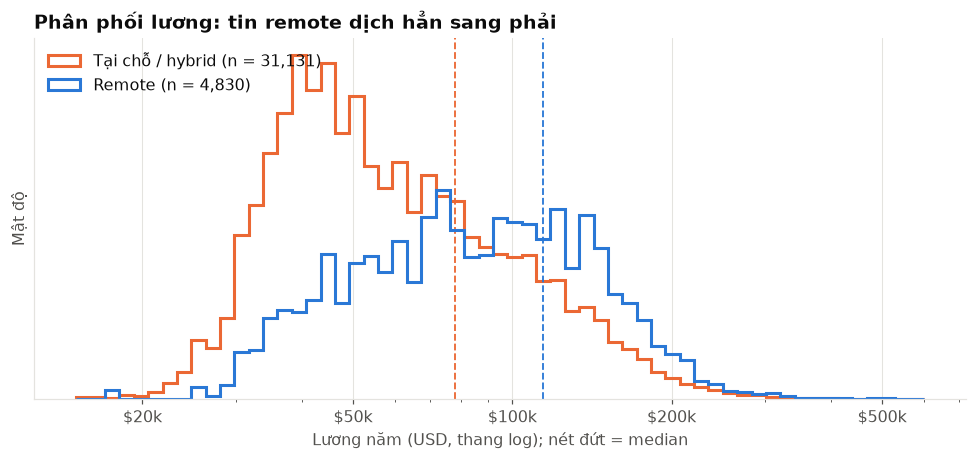

In [16]:
r = q2['remote_label'] == 'Remote'
ratio, lo, hi = bootstrap_ratio(q2.loc[r, 'annual_salary'], q2.loc[~r, 'annual_salary'], stat=np.median)
print(f"Median remote: ${q2.loc[r, 'annual_salary'].median():,.0f} | tại chỗ: ${q2.loc[~r, 'annual_salary'].median():,.0f}")
print(f'Tỉ số median remote / tại chỗ: {ratio:.3f} (95% CI {lo:.3f}–{hi:.3f}) → remote cao hơn {ratio - 1:.1%}')
mw = sps.mannwhitneyu(q2.loc[r, 'annual_salary'], q2.loc[~r, 'annual_salary'])
auc = mw.statistic / (r.sum() * (~r).sum())
print(f'Mann–Whitney p = {mw.pvalue:.1e}; xác suất một tin remote ngẫu nhiên trả cao hơn một tin tại chỗ ngẫu nhiên = {auc:.2f}')

fig, ax = plt.subplots(figsize=(9, 4.3))
bins = np.logspace(np.log10(15_000), np.log10(600_000), 60)
for lab, c in [('Tại chỗ / hybrid', SERIES[1]), ('Remote', SERIES[0])]:
    v = q2.loc[q2['remote_label'] == lab, 'annual_salary']
    ax.hist(v, bins=bins, density=True, histtype='step', linewidth=2, color=c, label=f'{lab} (n = {len(v):,})')
    ax.axvline(v.median(), color=c, linestyle='--', linewidth=1.2)
ax.set_xscale('log'); ax.set_xticks([20_000, 50_000, 100_000, 200_000, 500_000])
ax.xaxis.set_major_formatter(usd); ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks([]); ax.set_ylabel('Mật độ')
ax.set_xlabel('Lương năm (USD, thang log); nét đứt = median')
ax.set_title('Phân phối lương: tin remote dịch hẳn sang phải')
ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

### Phân tích 2 – Remote và tại chỗ có khác nhau về *loại công việc* không? (tìm confounder)
Nếu tin remote tập trung ở cấp bậc cao, nhóm IT, việc trả lương năm… thì chênh lệch thô một phần là do *loại công việc* chứ không phải remote.

remote_label,Tại chỗ / hybrid,Remote
Mid-Senior trở lên,38.500,52.900
Entry level / Internship,28.400,13.000
Nhóm IT hoặc Engineering,15.300,25.200
Health Care / Management,24.900,7.400
Trả lương theo năm,54.200,69.300
Hợp đồng (Contract),9.400,18.900


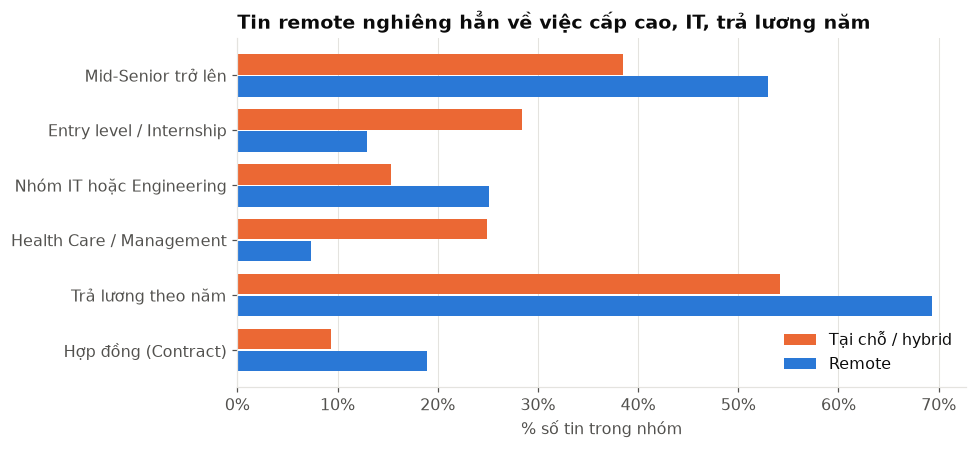

In [17]:
comp = pd.DataFrame({
    'Mid-Senior trở lên': q2['experience_level'].isin(['Mid-Senior level', 'Director', 'Executive']),
    'Entry level / Internship': q2['experience_level'].isin(['Entry level', 'Internship']),
    'Nhóm IT hoặc Engineering': q2['function_abr'].isin(['IT', 'ENG']),
    'Health Care / Management': q2['function_abr'].isin(['HCPR', 'MGMT']),
    'Trả lương theo năm': q2['pay_period_fixed'] == 'YEARLY',
    'Hợp đồng (Contract)': q2['work_type'] == 'Contract',
}).groupby(q2['remote_label']).mean().T[['Tại chỗ / hybrid', 'Remote']]
display((comp * 100).round(1))
fig, ax = plt.subplots(figsize=(9, 4.2))
y = np.arange(len(comp)); h = 0.38
ax.barh(y - h/2 - 0.01, comp['Tại chỗ / hybrid'], height=h, color=SERIES[1], label='Tại chỗ / hybrid')
ax.barh(y + h/2 + 0.01, comp['Remote'], height=h, color=SERIES[0], label='Remote')
ax.set_yticks(y); ax.set_yticklabels(comp.index); ax.invert_yaxis()
ax.xaxis.set_major_formatter(pct); ax.set_xlabel('% số tin trong nhóm')
ax.set_title('Tin remote nghiêng hẳn về việc cấp cao, IT, trả lương năm')
ax.legend(loc='lower right'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

### Phân tích 3 – So sánh công việc tương đương (D4, D5)
So sánh remote với tại chỗ **trong từng nhóm con**, thêm dần biến kiểm soát: cùng cấp bậc → cùng cấp bậc × chức năng → cùng cấp bậc × chức năng × đơn vị lương. Trong mỗi nhóm con tính tỉ số median lương remote / tại chỗ, chỉ giữ nhóm con có ≥ 10 tin mỗi bên, rồi gộp bằng trung bình có trọng số. Phần chênh lệch *mất đi* khi thêm biến là phần do **loại công việc**, không phải do remote. CI: bootstrap 200 lần.

In [18]:
COLS2 = ['remote_label', 'annual_salary', 'experience_level', 'job_function', 'pay_period_fixed', 'company']

def remote_gap(d, by, min_n=10):
    """% chênh lệch lương remote so với tại chỗ, so sánh trong từng nhóm con `by`."""
    return compare_within_groups(d, by, 'remote_label', 'annual_salary', 'Remote', 'Tại chỗ / hybrid',
                                 agg='median', min_n=min_n, log_ratio=True)

steps2 = {
    'Thô (không kiểm soát)': [],
    'Cùng cấp bậc': ['experience_level'],
    'Cùng cấp bậc × chức năng': ['experience_level', 'job_function'],
    'Cùng cấp bậc × chức năng × đơn vị lương': ['experience_level', 'job_function', 'pay_period_fixed'],
}
rows = []
for name, by in steps2.items():
    est, lo, hi = bootstrap_df(q2[COLS2], lambda d: remote_gap(d, by)[0], n_boot=200)
    tab = remote_gap(q2, by)[1]
    rows.append({'cách so sánh': name, 'chênh lệch': est, 'lo': lo, 'hi': hi,
                 'số nhóm con': len(tab), '% tin được dùng': (tab['n_1'] + tab['n_0']).sum() / len(q2)})
prog = pd.DataFrame(rows).set_index('cách so sánh')
raw_p, full_p = prog['chênh lệch'].iloc[0], prog['chênh lệch'].iloc[-1]
print(f'Phần chênh lệch thô (thang log) được giải thích bởi loại công việc: {1 - np.log1p(full_p) / np.log1p(raw_p):.0%}')
prog.style.format({'chênh lệch': '{:+.1%}', 'lo': '{:+.1%}', 'hi': '{:+.1%}', 'số nhóm con': '{:,}', '% tin được dùng': '{:.0%}'})

Phần chênh lệch thô (thang log) được giải thích bởi loại công việc: 67%


,chênh lệch,lo,hi,số nhóm con,% tin được dùng
cách so sánh,,,,,
Thô (không kiểm soát),+46.7%,+43.5%,+48.4%,1,100%
Cùng cấp bậc,+24.2%,+22.1%,+26.2%,7,100%
Cùng cấp bậc × chức năng,+17.6%,+15.6%,+19.6%,89,90%
Cùng cấp bậc × chức năng × đơn vị lương,+13.3%,+11.7%,+16.1%,115,76%


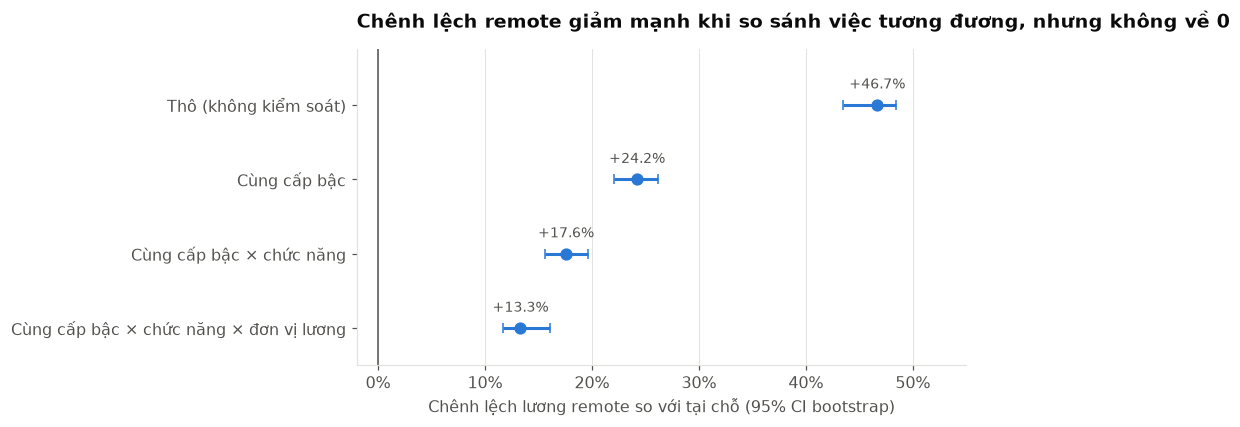

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(prog))
ax.errorbar(prog['chênh lệch'], y, xerr=[prog['chênh lệch'] - prog['lo'], prog['hi'] - prog['chênh lệch']],
            fmt='o', color=SERIES[0], capsize=3)
for yi, v in zip(y, prog['chênh lệch']):
    ax.text(v, yi - 0.22, f'{v:+.1%}', ha='center', fontsize=9, color=TEXT_2)
ax.axvline(0, color=TEXT_2, linewidth=1)
ax.set_yticks(y); ax.set_yticklabels(prog.index); ax.invert_yaxis()
ax.xaxis.set_major_formatter(pct); ax.set_xlim(-0.02, 0.55)
ax.set_xlabel('Chênh lệch lương remote so với tại chỗ (95% CI bootstrap)')
ax.set_title('Chênh lệch remote giảm mạnh khi so sánh việc tương đương, nhưng không về 0', pad=14)
ax.set_ylim(len(prog) - 0.5, -0.75)
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

Số nhóm con có ≥ 20 tin mỗi bên: 61 | nhóm con có remote cao hơn: 82%


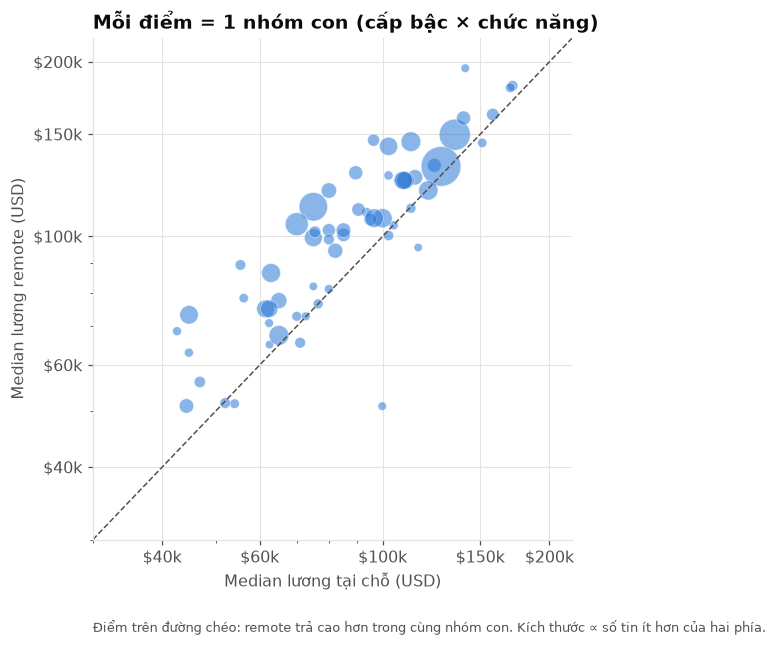

In [20]:
# Từng nhóm con (cấp bậc × chức năng): điểm nằm trên đường chéo = remote trả cao hơn trong cùng nhóm con
_, cells2 = remote_gap(q2, ['experience_level', 'job_function'], min_n=20)
print(f'Số nhóm con có ≥ 20 tin mỗi bên: {len(cells2)} | nhóm con có remote cao hơn: {(cells2["chenh_lech"] > 0).mean():.0%}')
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(cells2['gia_tri_0'], cells2['gia_tri_1'], s=cells2['trong_so'] * 1.5, color=SERIES[0], alpha=0.55,
           edgecolor='white', linewidth=0.5)
lim = [30_000, 220_000]
ax.plot(lim, lim, color=TEXT_2, linestyle='--', linewidth=1)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(lim); ax.set_ylim(lim)
for a in (ax.xaxis, ax.yaxis):
    a.set_major_formatter(usd); a.set_minor_formatter(plt.NullFormatter())
ax.set_xticks([40_000, 60_000, 100_000, 150_000, 200_000]); ax.set_yticks([40_000, 60_000, 100_000, 150_000, 200_000])
ax.set_xlabel('Median lương tại chỗ (USD)'); ax.set_ylabel('Median lương remote (USD)')
ax.set_title('Mỗi điểm = 1 nhóm con (cấp bậc × chức năng)')
note(ax, 'Điểm trên đường chéo: remote trả cao hơn trong cùng nhóm con. Kích thước ∝ số tin ít hơn của hai phía.')
plt.tight_layout(); plt.show()

### Phân tích 4 – Kiểm tra độ vững (D6)
Chạy lại phép so sánh *cùng cấp bậc × chức năng × đơn vị lương* với các lựa chọn khác: ngưỡng số tin tối thiểu trong nhóm con, chỉ việc trả lương năm, không sửa lỗi đơn vị, khoảng lương hẹp hơn, loại bản sao, chỉ Full-time, bỏ tin tuyển toàn quốc. Cuối cùng là **so sánh trong cùng một công ty** (nhóm con = công ty × cấp bậc, ≥ 3 tin mỗi bên). CI: bootstrap 100 lần.

In [21]:
BY2 = steps2['Cùng cấp bậc × chức năng × đơn vị lương']
alt2 = {
    'Gốc (≥ 10 tin mỗi bên)': (q2, BY2, 10),
    'Ngưỡng ≥ 20 tin mỗi bên': (q2, BY2, 20),
    'Chỉ trả lương theo năm (YEARLY)': (q2[q2['pay_period_fixed'] == 'YEARLY'], BY2, 10),
    'Không sửa đơn vị (bỏ 402 tin đã sửa)': (q2[q2['salary_status'] != 'repaired'], BY2, 10),
    'Khoảng lương hẹp hơn [$20k; $500k]': (q2[q2['annual_salary'].between(20_000, 500_000)], BY2, 10),
    'Loại bản sao đa địa điểm': (q2.drop_duplicates(['company_name', 'title', 'annual_salary']), BY2, 10),
    'Chỉ Full-time': (q2[q2['work_type'] == 'Full-time'], BY2, 10),
    'Bỏ tin tuyển toàn quốc': (q2[~q2['is_nationwide']], BY2, 10),
    'Trong cùng công ty × cấp bậc (≥ 3 tin mỗi bên)': (q2, ['company', 'experience_level'], 3),
}
rows = []
for name, (d, by, mn) in alt2.items():
    est, lo, hi = bootstrap_df(d[COLS2], lambda x: remote_gap(x, by, mn)[0], n_boot=100)
    rows.append({'phương án': name, 'chênh lệch': est, 'lo': lo, 'hi': hi, 'n': len(d),
                 'số nhóm con': len(remote_gap(d, by, mn)[1])})
rob2 = pd.DataFrame(rows).set_index('phương án')
rob2.style.format({'chênh lệch': '{:+.1%}', 'lo': '{:+.1%}', 'hi': '{:+.1%}', 'n': '{:,}', 'số nhóm con': '{:,}'})

,chênh lệch,lo,hi,n,số nhóm con
phương án,,,,,
Gốc (≥ 10 tin mỗi bên),+13.3%,+11.9%,+16.3%,"35,961",115
Ngưỡng ≥ 20 tin mỗi bên,+13.6%,+11.6%,+16.8%,"35,961",62
Chỉ trả lương theo năm (YEARLY),+10.9%,+8.4%,+13.7%,"20,205",71
Không sửa đơn vị (bỏ 402 tin đã sửa),+13.0%,+11.7%,+15.8%,"35,559",114
Khoảng lương hẹp hơn [$20k; $500k],+13.2%,+11.5%,+15.8%,"35,886",114
Loại bản sao đa địa điểm,+13.5%,+11.8%,+16.5%,"33,381",111
Chỉ Full-time,+11.8%,+9.3%,+14.5%,"29,061",85
Bỏ tin tuyển toàn quốc,+12.7%,+10.0%,+16.1%,"33,372",61
Trong cùng công ty × cấp bậc (≥ 3 tin mỗi bên),+12.6%,+8.3%,+18.2%,"35,961",154


### Kết luận Q2

**Trả lời.** Về số liệu thô, tin remote có median **$114,400** so với **$78,000** của tin tại chỗ, tức **cao hơn 46.7%** (95% CI 42.8–48.4%). Lấy ngẫu nhiên một tin remote và một tin tại chỗ, tin remote trả cao hơn với xác suất 0.66 (Mann–Whitney p ≈ 4·10⁻²⁹⁴). **Phần lớn chênh lệch này là do *loại công việc*:** tin remote thường là việc cấp cao, thuộc IT/Engineering và trả lương theo năm – 52.9% tin remote là Mid-Senior trở lên (tin tại chỗ: 38.5%), 25.2% thuộc IT/Engineering (15.3%), và chỉ 13.0% là Entry/Internship (28.4%).

Khi so sánh **công việc tương đương**, mức chênh giảm dần: +46.7% (thô) → +24.2% (cùng cấp bậc) → +17.6% (cùng cấp bậc × chức năng) → **+13.3%** (CI +11.7 … +16.1%) khi cùng cấp bậc × chức năng × đơn vị lương. Khoảng **2/3** chênh lệch thô (thang log) được giải thích bởi loại công việc. Trong **82%** của 61 nhóm con cấp bậc × chức năng (≥ 20 tin mỗi bên), median remote cao hơn.

**Độ vững (D6):** mức chênh luôn dương và CI không chứa 0 ở mọi phương án, dao động **+10.9% đến +13.6%**: đổi ngưỡng số tin, chỉ việc trả lương năm, không sửa đơn vị, khoảng lương hẹp, loại bản sao, chỉ Full-time, bỏ tin toàn quốc. Khi **so sánh trong cùng một công ty** (nhóm con = công ty × cấp bậc), remote vẫn cao hơn **+12.6%** (CI +8.3 … +18.2%).

**Ý nghĩa thực tế.** Remote **không bị trả thấp hơn**. Với công việc tương đương, tin remote công bố lương cao hơn khoảng **11–14%**, còn con số thô +47% phóng đại mức chênh thật khoảng 3–4 lần. Người tìm việc không cần chấp nhận lương thấp hơn để được remote. Nhà tuyển dụng cần biết rằng tin remote cạnh tranh trên thị trường toàn quốc nên mặt bằng lương cao hơn. Một khả năng chưa kiểm tra được là tin remote thường do công ty ở vùng chi phí sinh hoạt cao đăng và cạnh tranh ứng viên trên toàn quốc.

**Hạn chế.** (1) Đây là lương *công bố* trong tin, không phải lương thực nhận, và chỉ tính trên 29% tin có lương; công ty chọn công bố có thể khác công ty không công bố. (2) `remote_allowed = 0` gộp cả tin tại chỗ, hybrid và tin không ghi rõ. (3) So sánh trong nhóm con chỉ dùng các nhóm con đủ dữ liệu ở cả hai phía (76% số tin ở bước cuối), và chưa kiểm soát cùng lúc bang/ngành vì nhóm con sẽ quá nhỏ. (4) Còn biến không quan sát được: trong cùng chức năng và cấp bậc, vị trí remote có thể là công việc "khó" hơn (ví dụ yêu cầu tự quản lý cao). Vì vậy +13% là *mối liên hệ sau khi kiểm soát*, chưa chắc là hiệu ứng nhân quả.

---
## Q3 – Nghề nào có "bậc thang lương" dốc nhất từ Entry lên Mid-Senior?
*Người phụ trách: Huỳnh Huy Hoàng (24120181)*

**Câu hỏi.** Trong mỗi nhóm chức năng, median lương cấp **Mid-Senior** gấp bao nhiêu lần cấp **Entry** (kèm CI bootstrap)? Nhóm nào có bậc thang dốc nhất/thoải nhất, và thứ hạng này có giữ nguyên khi đổi cách lọc dữ liệu không?

**Động lực.** Sinh viên chọn hướng nghề thường chỉ nhìn lương khởi điểm. Nhưng một nghề lương khởi điểm cao mà tăng chậm có thể kém hấp dẫn hơn một nghề khởi điểm thấp nhưng tăng nhanh. Kết quả giúp người học định hướng và giúp trường/khoa tư vấn nghề nghiệp.

### Tiền xử lý
1. Tin có lương năm hợp lệ, **Full-time** (để so sánh công bằng – part-time/contract có cách trả khác), cấp bậc thuộc {Entry, Associate, Mid-Senior, Director}.
2. **Ghép (D1)** với `jobs/job_skills.csv` + `mappings/skills.csv` để lấy **tất cả** nhóm chức năng của mỗi tin (1–3 nhóm). Bảng chuyển sang **dạng dài** – một tin xuất hiện một lần cho mỗi nhóm chức năng của nó – nên số dòng tăng; đây là chủ đích (một tin "IT + Engineering" đóng góp vào cả hai nhóm).
3. **Reshape (D2):** `pivot_table` thành ma trận chức năng × cấp bậc (median, số tin), sau đó `melt` ngược lại để vẽ đường bậc thang.
4. Biến dẫn xuất (D3): `ladder = median(Mid-Senior) / median(Entry)`. Chỉ tính cho nhóm có ≥ 30 tin ở cả hai cấp.

In [22]:
LEVELS = ['Entry level', 'Associate', 'Mid-Senior level', 'Director']
steps = [('Bảng đã làm sạch', len(df))]
base3 = df[df['annual_salary'].notna()]
steps.append(('Có lương năm hợp lệ', len(base3)))
base3 = base3[base3['work_type'] == 'Full-time']
steps.append(('Chỉ Full-time', len(base3)))
base3 = base3[base3['experience_level'].isin(LEVELS)]
steps.append(('Cấp bậc ∈ {Entry, Associate, Mid-Senior, Director}', len(base3)))

jf = load_job_functions()
COLS3 = ['job_id', 'annual_salary', 'experience_level', 'pay_period_fixed', 'salary_status', 'company_name', 'title']
long3 = base3[COLS3].merge(jf[['job_id', 'skill_name', 'rank']], on='job_id', how='inner', validate='1:m')
steps.append(('Ghép job_skills → dạng dài (tin × nhóm chức năng)', len(long3)))
display(row_report(steps))
print(f"Số tin không có nhóm chức năng (mất khi inner join): {(~base3['job_id'].isin(jf['job_id'])).sum():,}")
print(f"Số nhóm chức năng trung bình mỗi tin: {len(long3) / long3['job_id'].nunique():.2f}")

,bước,số dòng,thay đổi
0,Bảng đã làm sạch,123849,0
1,Có lương năm hợp lệ,35961,-87888
2,Chỉ Full-time,29061,-6900
3,"Cấp bậc ∈ {Entry, Associate, Mid-Senior, Direc...",21697,-7364
4,Ghép job_skills → dạng dài (tin × nhóm chức năng),37514,15817


Số tin không có nhóm chức năng (mất khi inner join): 0
Số nhóm chức năng trung bình mỗi tin: 1.73


Nhóm chức năng đủ dữ liệu (≥ 30 tin ở Entry và Mid-Senior): 31 / 35
Bị loại: Advertising, Purchasing, Science, Strategy/Planning


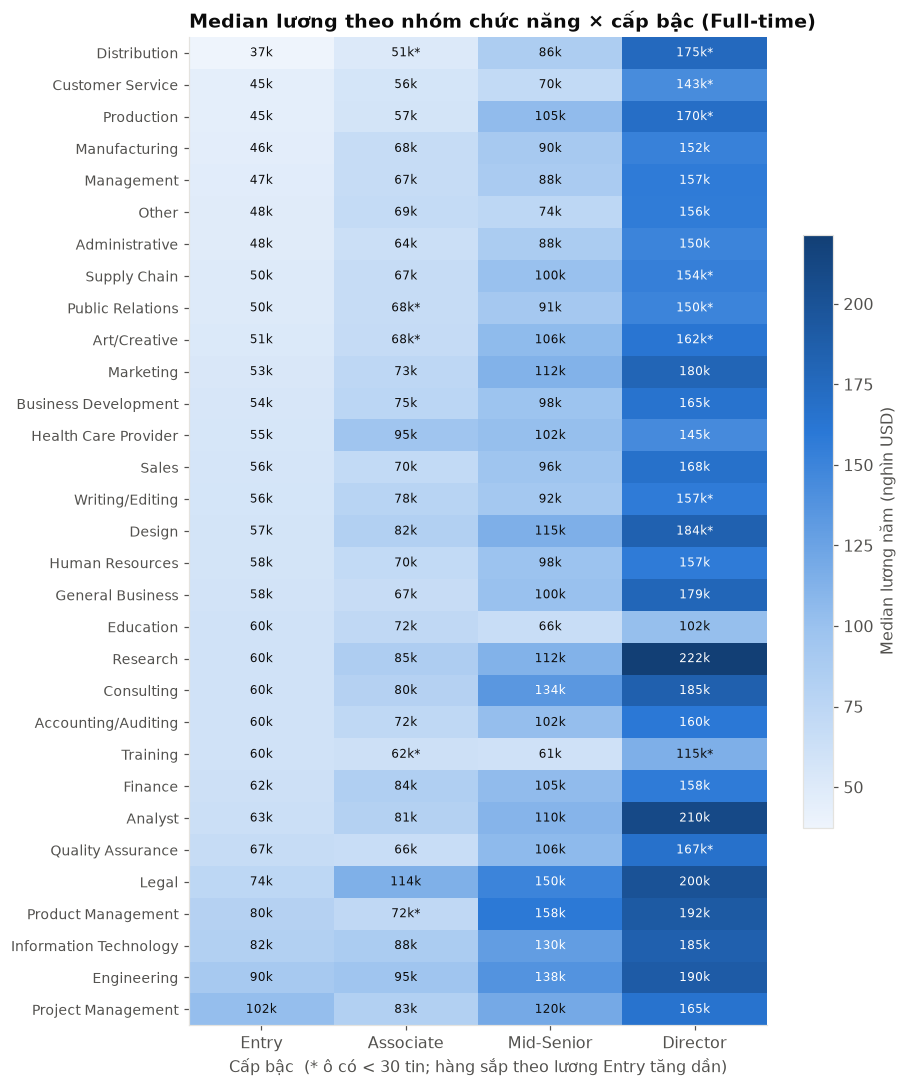

In [23]:
# D2 – pivot: chức năng × cấp bậc
med = long3.pivot_table(index='skill_name', columns='experience_level', values='annual_salary', aggfunc='median')[LEVELS]
cnt = long3.pivot_table(index='skill_name', columns='experience_level', values='annual_salary', aggfunc='size')[LEVELS]
ok = (cnt['Entry level'] >= 30) & (cnt['Mid-Senior level'] >= 30)
print(f'Nhóm chức năng đủ dữ liệu (≥ 30 tin ở Entry và Mid-Senior): {ok.sum()} / {len(ok)}')
print('Bị loại:', ', '.join(ok[~ok].index))
med_ok = med[ok].sort_values('Entry level')

fig, ax = plt.subplots(figsize=(8.5, 10))
im = ax.imshow(med_ok.to_numpy() / 1000, cmap=SEQ_CMAP, aspect='auto')
ax.set_xticks(range(len(LEVELS))); ax.set_xticklabels(['Entry', 'Associate', 'Mid-Senior', 'Director'])
ax.set_yticks(range(len(med_ok))); ax.set_yticklabels(med_ok.index, fontsize=9)
for i in range(med_ok.shape[0]):
    for j in range(med_ok.shape[1]):
        v = med_ok.iloc[i, j]; n = cnt.loc[med_ok.index[i], LEVELS[j]]
        if pd.notna(v):
            ax.text(j, i, f'{v/1000:.0f}k' + ('*' if n < 30 else ''), ha='center', va='center', fontsize=8,
                    color='white' if v > 120_000 else '#0b0b0b')
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.6, label='Median lương năm (nghìn USD)')
ax.set_title('Median lương theo nhóm chức năng × cấp bậc (Full-time)')
ax.set_xlabel('Cấp bậc  (* ô có < 30 tin; hàng sắp theo lương Entry tăng dần)')
plt.tight_layout(); plt.show()

### Phân tích 1 – Hệ số bậc thang và khoảng tin cậy (D5)
Với mỗi nhóm, `ladder = median(Mid-Senior) / median(Entry)`. CI 95% bằng **bootstrap**: rút lại (có hoàn lại) các tin Mid-Senior và các tin Entry của nhóm đó, tính lại tỉ số, lặp 500 lần. Một nhóm được coi là thoải/dốc hơn thị trường *một cách đáng tin* khi toàn bộ CI của nó nằm dưới/trên hệ số của toàn thị trường.

In [24]:
def ladder_table(d, min_n=30, with_ci=True, n_boot=500):
    """Bảng hệ số bậc thang Mid-Senior / Entry cho từng nhóm chức năng."""
    rows = []
    for f, g in d.groupby('skill_name'):
        e = g.loc[g['experience_level'] == 'Entry level', 'annual_salary']
        m = g.loc[g['experience_level'] == 'Mid-Senior level', 'annual_salary']
        if len(e) < min_n or len(m) < min_n:
            continue
        if with_ci:
            r, lo, hi = bootstrap_ratio(m, e, stat=np.median, n_boot=n_boot)
        else:
            r, lo, hi = m.median() / e.median(), np.nan, np.nan
        rows.append({'chức năng': f, 'entry_med': e.median(), 'mid_med': m.median(),
                     'ladder': r, 'lo': lo, 'hi': hi, 'n_entry': len(e), 'n_mid': len(m)})
    return pd.DataFrame(rows).set_index('chức năng').sort_values('ladder')

lad = ladder_table(long3)
mid_all = base3.loc[base3['experience_level'] == 'Mid-Senior level', 'annual_salary']
ent_all = base3.loc[base3['experience_level'] == 'Entry level', 'annual_salary']
overall, olo, ohi = bootstrap_ratio(mid_all, ent_all, stat=np.median)
print(f'Toàn bộ thị trường (Full-time): Mid-Senior / Entry = {overall:.2f} (95% CI {olo:.2f}–{ohi:.2f})')
lad.style.format({'entry_med': '${:,.0f}', 'mid_med': '${:,.0f}', 'ladder': '{:.2f}', 'lo': '{:.2f}', 'hi': '{:.2f}'})

Toàn bộ thị trường (Full-time): Mid-Senior / Entry = 1.95 (95% CI 1.91–1.99)


,entry_med,mid_med,ladder,lo,hi,n_entry,n_mid
chức năng,,,,,,,
Training,"$60,125","$61,061",1.02,0.79,1.23,104,129
Education,"$60,000","$66,158",1.10,0.98,1.35,120,78
Project Management,"$102,210","$120,000",1.17,1.12,1.32,130,620
Engineering,"$90,418","$137,500",1.52,1.45,1.60,679,1432
Other,"$47,778","$73,828",1.55,1.43,1.65,762,845
Customer Service,"$44,720","$70,000",1.57,1.44,1.71,261,226
Quality Assurance,"$67,439","$105,938",1.57,1.35,1.78,82,156
Information Technology,"$82,086","$130,000",1.58,1.51,1.66,1390,2345
Writing/Editing,"$56,185","$92,500",1.65,1.43,2.02,54,114


Thoải hơn thị trường (CI < 1.95): 15 nhóm → Training, Education, Project Management, Engineering, Other, Customer Service, Quality Assurance, Information Technology, Finance, Human Resources, Accounting/Auditing, Sales, Analyst, Business Development, Administrative
Dốc hơn thị trường (CI > 1.95): 1 nhóm → Distribution


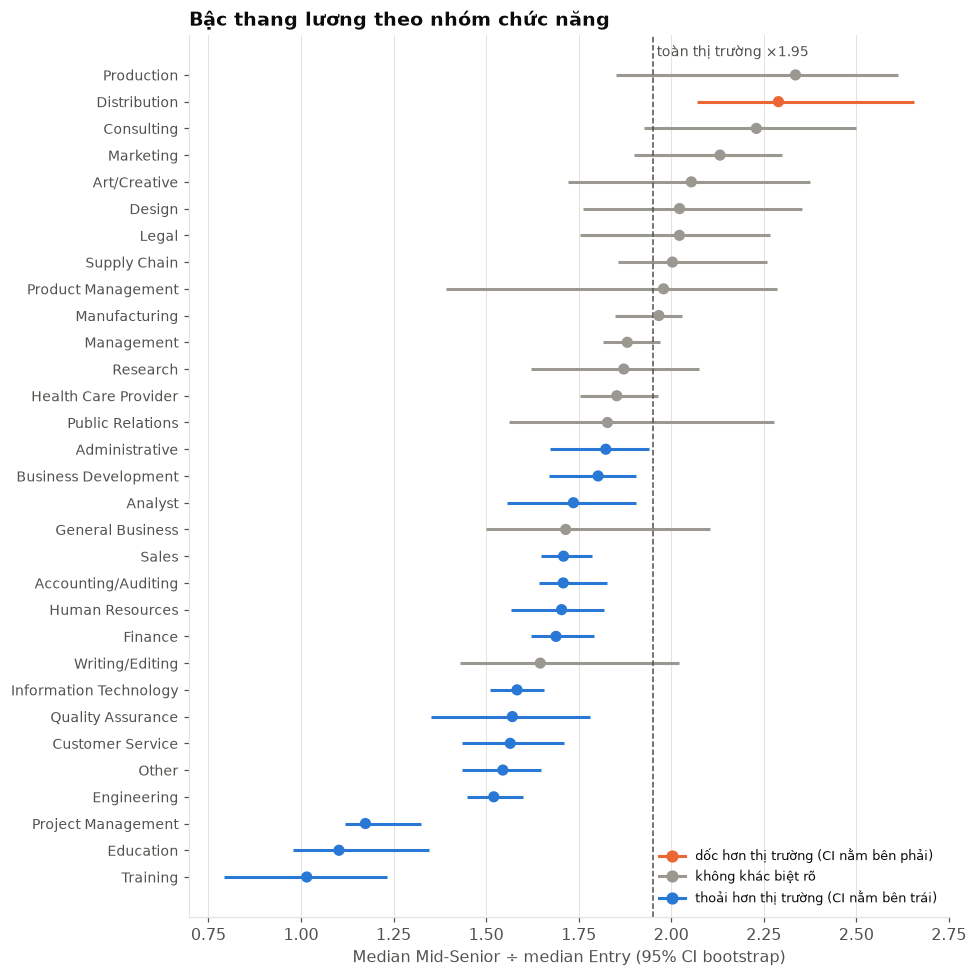

In [25]:
fig, ax = plt.subplots(figsize=(9, 9))
y = np.arange(len(lad))
colors = [SERIES[1] if lo > overall else (SERIES[0] if hi < overall else NEUTRAL) for lo, hi in zip(lad['lo'], lad['hi'])]
ax.hlines(y, lad['lo'], lad['hi'], color=colors, linewidth=2)
ax.scatter(lad['ladder'], y, color=colors, s=40, zorder=3)
ax.axvline(overall, color=TEXT_2, linestyle='--', linewidth=1)
ax.text(overall, len(lad) - 0.3, f' toàn thị trường ×{overall:.2f}', color=TEXT_2, fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(lad.index, fontsize=9)
ax.set_xlabel('Median Mid-Senior ÷ median Entry (95% CI bootstrap)')
ax.set_title('Bậc thang lương theo nhóm chức năng')
print(f"Thoải hơn thị trường (CI < {overall:.2f}): {(lad['hi'] < overall).sum()} nhóm → {', '.join(lad.index[lad['hi'] < overall])}")
print(f"Dốc hơn thị trường (CI > {overall:.2f}): {(lad['lo'] > overall).sum()} nhóm → {', '.join(lad.index[lad['lo'] > overall])}")
ax.grid(axis='y', visible=False)
ax.legend([Line2D([0], [0], color=c, marker='o') for c in [SERIES[1], NEUTRAL, SERIES[0]]],
          ['dốc hơn thị trường (CI nằm bên phải)', 'không khác biệt rõ', 'thoải hơn thị trường (CI nằm bên trái)'],
          loc='lower right', fontsize=8.5)
plt.tight_layout(); plt.show()

,skill_name,experience_level,median_salary,step
0,Information Technology,Entry level,"82,086.000",0
1,Engineering,Entry level,"90,417.600",0
2,Sales,Entry level,"56,000.000",0
3,Health Care Provider,Entry level,"55,114.800",0
4,Marketing,Entry level,"52,770.000",0
5,Finance,Entry level,"62,172.775",0
6,Information Technology,Associate,"87,500.000",1
7,Engineering,Associate,"95,000.000",1


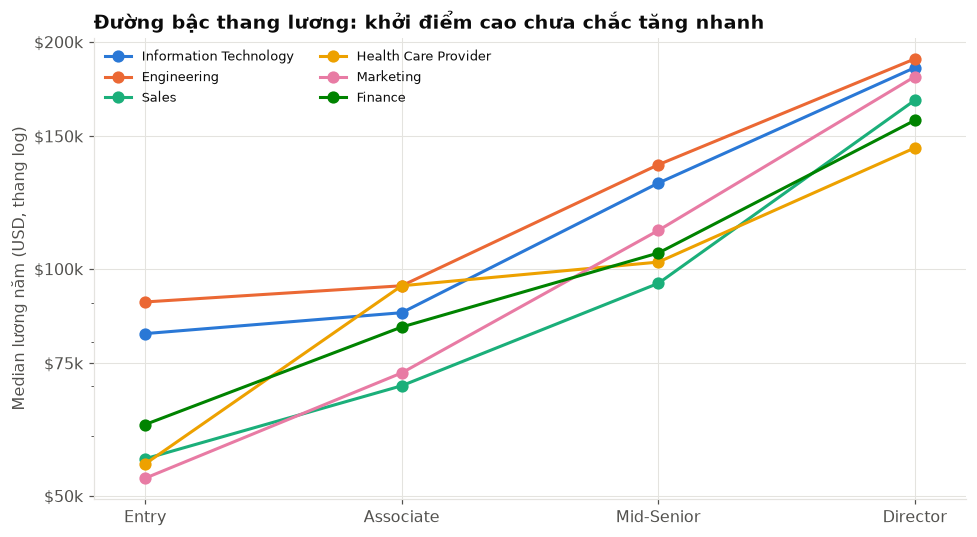

In [26]:
# D2 – melt ma trận median về dạng dài để vẽ đường bậc thang cho một số nghề tiêu biểu
pick = ['Information Technology', 'Engineering', 'Sales', 'Health Care Provider', 'Marketing', 'Finance']
ladder_long = (med.loc[pick].reset_index()
                 .melt(id_vars='skill_name', var_name='experience_level', value_name='median_salary'))
ladder_long['step'] = ladder_long['experience_level'].map({l: i for i, l in enumerate(LEVELS)})
display(ladder_long.head(8))
fig, ax = plt.subplots(figsize=(9, 5))
for k, f in enumerate(pick):
    g = ladder_long[ladder_long['skill_name'] == f].sort_values('step')
    ax.plot(g['step'], g['median_salary'], marker='o', color=SERIES[k], label=f)
ax.set_yscale('log'); ax.set_yticks([50_000, 75_000, 100_000, 150_000, 200_000])
ax.yaxis.set_major_formatter(usd); ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xticks(range(4)); ax.set_xticklabels(['Entry', 'Associate', 'Mid-Senior', 'Director']); ax.set_xlim(-0.2, 3.2)
ax.set_ylabel('Median lương năm (USD, thang log)')
ax.set_title('Đường bậc thang lương: khởi điểm cao chưa chắc tăng nhanh')
ax.legend(loc='upper left', fontsize=8.5, ncol=2)
plt.tight_layout(); plt.show()

### Phân tích 2 – Kiểm tra độ vững của thứ hạng (D6)
So sánh hệ số bậc thang dưới các lựa chọn khác. Đo độ ổn định bằng **tương quan hạng Spearman** giữa thứ hạng gốc và thứ hạng thay thế (1 = giữ nguyên thứ tự).
- **Chỉ YEARLY:** bỏ các tin trả theo giờ (việc Entry hay trả theo giờ, có thể làm bậc thang dốc giả tạo).
- **Mọi loại hợp đồng:** không lọc Full-time.
- **Không sửa đơn vị:** bỏ các tin đã được sửa lỗi đơn vị lương.
- **Chỉ chức năng chính:** mỗi tin chỉ thuộc nhóm đầu tiên (không dùng dạng dài đa nhãn).
- **Loại bản sao đa địa điểm.**

In [27]:
def long_from(d):
    return d[COLS3].merge(jf[['job_id', 'skill_name', 'rank']], on='job_id', how='inner')

all_types = df[df['annual_salary'].notna() & df['experience_level'].isin(LEVELS)]
variants = {
    'Chỉ YEARLY': long3[long3['pay_period_fixed'] == 'YEARLY'],
    'Mọi loại hợp đồng': long_from(all_types),
    'Không sửa đơn vị': long3[long3['salary_status'] != 'repaired'],
    'Chỉ chức năng chính': long3[long3['rank'] == 0],
    'Loại bản sao đa địa điểm': long3.drop_duplicates(['company_name', 'title', 'annual_salary', 'skill_name']),
}
comp3 = pd.DataFrame({'Gốc': lad['ladder']})
for k, d in variants.items():
    comp3[k] = ladder_table(d, with_ci=False)['ladder']
rho = {k: sps.spearmanr(comp3['Gốc'], comp3[k], nan_policy='omit').statistic for k in variants}
display(pd.Series(rho, name='Spearman ρ với thứ hạng gốc').round(2).to_frame())
summary3 = {}
for k in comp3.columns:
    s_ = comp3[k].dropna().sort_values()
    summary3[k] = {'số nhóm': len(s_), '5 thoải nhất': ', '.join(s_.index[:5]), '5 dốc nhất': ', '.join(s_.index[-5:][::-1])}
display(pd.DataFrame(summary3).T)
y_ = base3[base3['pay_period_fixed'] == 'YEARLY']
oy = bootstrap_ratio(y_.loc[y_['experience_level'] == 'Mid-Senior level', 'annual_salary'],
                     y_.loc[y_['experience_level'] == 'Entry level', 'annual_salary'], stat=np.median)
print(f'Toàn thị trường, chỉ YEARLY: Mid-Senior / Entry = {oy[0]:.2f} (95% CI {oy[1]:.2f}–{oy[2]:.2f})')
comp3.round(2).sort_values('Gốc')

,Spearman ρ với thứ hạng gốc
Chỉ YEARLY,0.450
Mọi loại hợp đồng,0.940
Không sửa đơn vị,1.000
Chỉ chức năng chính,0.740
Loại bản sao đa địa điểm,0.990


,số nhóm,5 thoải nhất,5 dốc nhất
Gốc,31,"Training, Education, Project Management, Engin...","Production, Distribution, Consulting, Marketin..."
Chỉ YEARLY,27,"Education, Project Management, Training, Quali...","Consulting, Marketing, Public Relations, Legal..."
Mọi loại hợp đồng,31,"Training, Project Management, Education, Engin...","Production, Distribution, Marketing, Consultin..."
Không sửa đơn vị,31,"Training, Education, Project Management, Engin...","Production, Distribution, Consulting, Marketin..."
Chỉ chức năng chính,22,"Education, Project Management, Product Managem...","Manufacturing, Design, Legal, Marketing, Busin..."
Loại bản sao đa địa điểm,31,"Training, Education, Project Management, Engin...","Production, Distribution, Art/Creative, Consul..."


Toàn thị trường, chỉ YEARLY: Mid-Senior / Entry = 1.49 (95% CI 1.48–1.53)


,Gốc,Chỉ YEARLY,Mọi loại hợp đồng,Không sửa đơn vị,Chỉ chức năng chính,Loại bản sao đa địa điểm
chức năng,,,,,,
Training,1.020,1.200,1.050,1.000,NaN,1.040
Education,1.100,1.130,1.200,1.100,1.050,1.100
Project Management,1.170,1.170,1.180,1.170,1.170,1.170
Engineering,1.520,1.380,1.510,1.520,1.530,1.520
Other,1.550,1.670,1.590,1.530,1.440,1.550
Customer Service,1.570,1.640,1.560,1.570,1.770,1.570
Quality Assurance,1.570,1.260,1.620,1.570,1.470,1.590
Information Technology,1.580,1.340,1.620,1.580,1.540,1.570
Writing/Editing,1.650,NaN,1.790,1.650,NaN,1.650


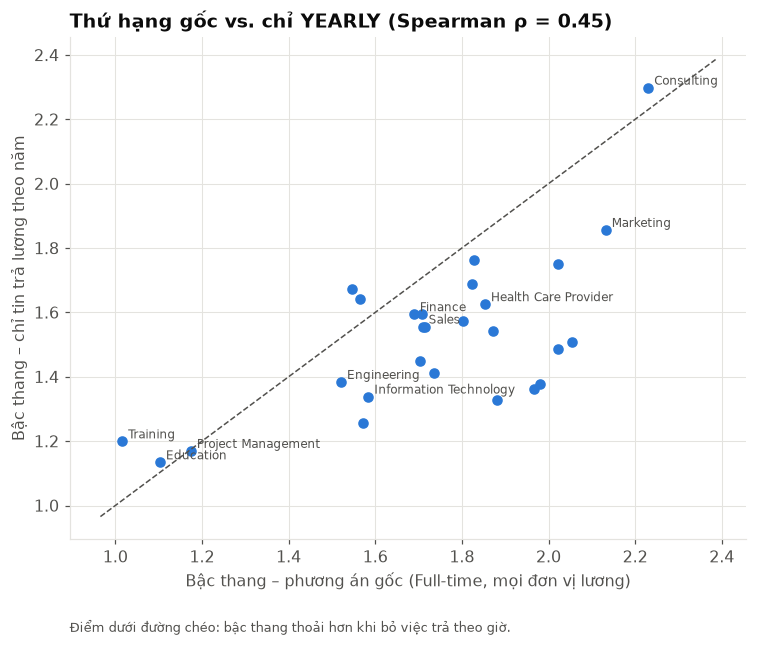

In [28]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(comp3['Gốc'], comp3['Chỉ YEARLY'], color=SERIES[0], s=35)
for f in comp3.index:
    if f in lad.index[:4].tolist() + lad.index[-4:].tolist() or f in pick:
        ax.annotate(f, (comp3.loc[f, 'Gốc'], comp3.loc[f, 'Chỉ YEARLY']), fontsize=8, color=TEXT_2,
                    xytext=(4, 2), textcoords='offset points')
lim = [comp3[['Gốc', 'Chỉ YEARLY']].min().min() - 0.05, comp3[['Gốc', 'Chỉ YEARLY']].max().max() + 0.05]
ax.plot(lim, lim, color=TEXT_2, linestyle='--', linewidth=1)
ax.set_xlabel('Bậc thang – phương án gốc (Full-time, mọi đơn vị lương)')
ax.set_ylabel('Bậc thang – chỉ tin trả lương theo năm')
ax.set_title(f"Thứ hạng gốc vs. chỉ YEARLY (Spearman ρ = {rho['Chỉ YEARLY']:.2f})")
note(ax, 'Điểm dưới đường chéo: bậc thang thoải hơn khi bỏ việc trả theo giờ.')
plt.tight_layout(); plt.show()

### Kết luận Q3

**Trả lời.** Trên toàn thị trường Full-time, median lương Mid-Senior bằng **1.95 lần** Entry (95% CI 1.91–1.99). Hệ số này rất khác nhau giữa các nghề, từ gần như **phẳng** ở *Training* (×1.02), *Education* (×1.10), *Project Management* (×1.17) đến **dốc** ở *Consulting* (×2.23), *Distribution* (×2.29), *Production* (×2.34). Có **15 nhóm thoải hơn thị trường** (CI nằm hoàn toàn dưới 1.95), trong đó có **IT (×1.58)** và **Engineering (×1.52)**. Chỉ **Distribution** dốc hơn thị trường một cách rõ ràng (CI 2.07–2.66), nhưng nhóm này chỉ có 37 tin Entry.

**Điều bất ngờ.** Hai nghề lớn có lương khởi điểm cao (Engineering $90k, IT $82k) lại có bậc thang **thoải hơn thị trường**. Ngược lại, Marketing khởi điểm chỉ $53k nhưng lên $112k ở Mid-Senior (×2.13). Dù vậy, xét **giá trị tuyệt đối**, IT/Engineering vẫn thuộc nhóm trả cao ở Mid-Senior ($130–138k). "Thoải" ở đây nghĩa là *tăng ít hơn theo tỉ lệ*, không phải *trả thấp*.

**Độ vững (D6).** Thứ hạng **rất ổn định** khi đổi loại hợp đồng (Spearman ρ = 0.94), bỏ tin sửa đơn vị (ρ = 1.00) và loại bản sao (ρ = 0.99); ổn định vừa phải khi chỉ dùng chức năng chính (ρ = 0.74). Tuy nhiên **chỉ ρ = 0.45 khi chỉ xét tin trả lương năm**: hệ số toàn thị trường giảm từ 1.95 xuống **1.49** (CI 1.48–1.53), và nhiều nghề (Management, Manufacturing, Product Management) thoải hẳn đi. Nghĩa là một phần lớn "độ dốc" đến từ việc **vị trí Entry ở các nghề này hay trả theo giờ** (lương thấp hơn). Các kết luận chính **giữ nguyên ở mọi phương án có đủ dữ liệu**: Education, Training, Project Management luôn thoải nhất; Consulting và Marketing luôn thuộc nhóm dốc; IT và Engineering luôn dưới mức thị trường (chỉ YEARLY: ×1.34 và ×1.38 so với ×1.49).

**Ý nghĩa thực tế.** Với sinh viên Khoa học Dữ liệu (IT/Analyst), lương khởi điểm đã cao nên dư địa tăng *theo tỉ lệ* thấp hơn các nghề kinh doanh/tư vấn. Khi so sánh các lời mời làm việc, nên nhìn cả mức lương ở cấp Mid-Senior chứ không chỉ lương khởi điểm.

**Hạn chế.** (1) Dữ liệu cắt ngang: so sánh *các tin khác nhau* ở hai cấp bậc, không theo dõi sự nghiệp của cùng một người. (2) "Mid-Senior level" là nhãn rộng của LinkedIn (từ 3 đến 15+ năm kinh nghiệm). (3) Một số nhóm có ít tin (Product Management chỉ 58 tin Entry → CI rất rộng 1.39–2.29). (4) Lương công bố là lương cơ bản, chưa gồm thưởng/cổ phiếu. (5) Ta so sánh 31 nhóm cùng lúc và bootstrap theo từng tin (coi các tin độc lập) nên CI có thể hẹp hơn thực tế đáng kể – các nhóm "khác thị trường" nằm sát ranh giới (vd. Business Development, Administrative, Distribution) có thể chỉ do ngẫu nhiên.

---
## Q4 – Công ty lớn có trả lương cao hơn cho công việc tương đương không?
*Người phụ trách: Huỳnh Huy Hoàng (24120181)*

**Câu hỏi.** Với công việc tương đương (cùng cấp bậc, cùng nhóm chức năng, cùng đơn vị trả lương), công ty có ≥ 10,000 nhân viên trả lương công bố cao hơn công ty nhỏ (1–49 nhân viên) bao nhiêu %? Kết luận từ số liệu thô có bị **đảo chiều** khi so sánh công việc tương đương không?

**Động lực.** Kinh tế học lao động ghi nhận "firm-size wage premium" – công ty lớn trả cao hơn. Sinh viên mới ra trường hay phân vân giữa startup và tập đoàn. Ở notebook 01, tương quan Spearman giữa lương và số nhân viên lại ≈ −0.05, nên cần kiểm tra xem đây là thật hay do **thành phần công việc**. Khi so sánh thô cho một kết luận nhưng so sánh trong từng nhóm con lại cho kết luận *ngược dấu*, hiện tượng đó gọi là **nghịch lý Simpson**.

### Tiền xử lý
1. **Ghép (D1)** postings ⨝ `companies` ⨝ `employee_counts` (đã làm ở notebook 01: giữ **snapshot số nhân viên mới nhất** của mỗi công ty, kiểm tra ghép m:1 không làm tăng dòng).
2. Biến dẫn xuất (D3): `employee_bucket` – 5 nhóm quy mô theo số nhân viên (1–49, 50–249, 250–999, 1k–9.9k, 10k+). Nhóm tham chiếu là 1–49. Cờ `staffing`: công ty thuộc ngành Staffing/Recruiting.
3. Chỉ giữ tin có lương hợp lệ **và** có số nhân viên.

In [29]:
steps = [('Bảng đã làm sạch', len(df))]
q4 = df[df['annual_salary'].notna()]
steps.append(('Có lương năm hợp lệ', len(q4)))
q4 = q4[q4['employee_bucket'].notna()].copy()
steps.append(('Có số nhân viên (ghép employee_counts thành công)', len(q4)))
display(row_report(steps))
print(f"Tin có lương nhưng không ghép được công ty: {df['annual_salary'].notna().sum() - len(q4):,} (công ty không có trang LinkedIn)")
q4['size'] = q4['employee_bucket'].astype(str)
SIZES = ['1–49', '50–249', '250–999', '1k–9.9k', '10k+']
q4['staffing'] = q4['company_industry'].fillna('').str.contains('Staffing|Recruiting')
print(q4.groupby('size').agg(n=('job_id', 'size'), median=('annual_salary', 'median'),
                             so_cong_ty=('company', 'nunique')).loc[SIZES])

,bước,số dòng,thay đổi
0,Bảng đã làm sạch,123849,0
1,Có lương năm hợp lệ,35961,-87888
2,Có số nhân viên (ghép employee_counts thành công),35457,-504


Tin có lương nhưng không ghép được công ty: 504 (công ty không có trang LinkedIn)
             n     median  so_cong_ty
size                                 
1–49      4976 88,000.000        3239
50–249    5942 87,500.000        2332
250–999   5548 85,000.000        1775
1k–9.9k  10061 75,000.000        2220
10k+      8930 83,200.000         747


### Phân tích 1 – Số liệu thô và thành phần công việc theo quy mô

,Trả lương theo giờ,Entry level,Mid-Senior trở lên,Health Care Provider,Công ty staffing/tuyển dụng,Hợp đồng (Contract)
size,,,,,,
1–49,26.200,9.400,34.900,6.700,40.400,9.300
50–249,38.400,18.400,42.800,13.200,45.500,14.300
250–999,46.800,29.300,45.800,13.300,34.400,18.500
1k–9.9k,46.900,34.300,42.800,10.400,17.200,9.700
10k+,44.500,27.400,37.500,7.800,7.800,5.300


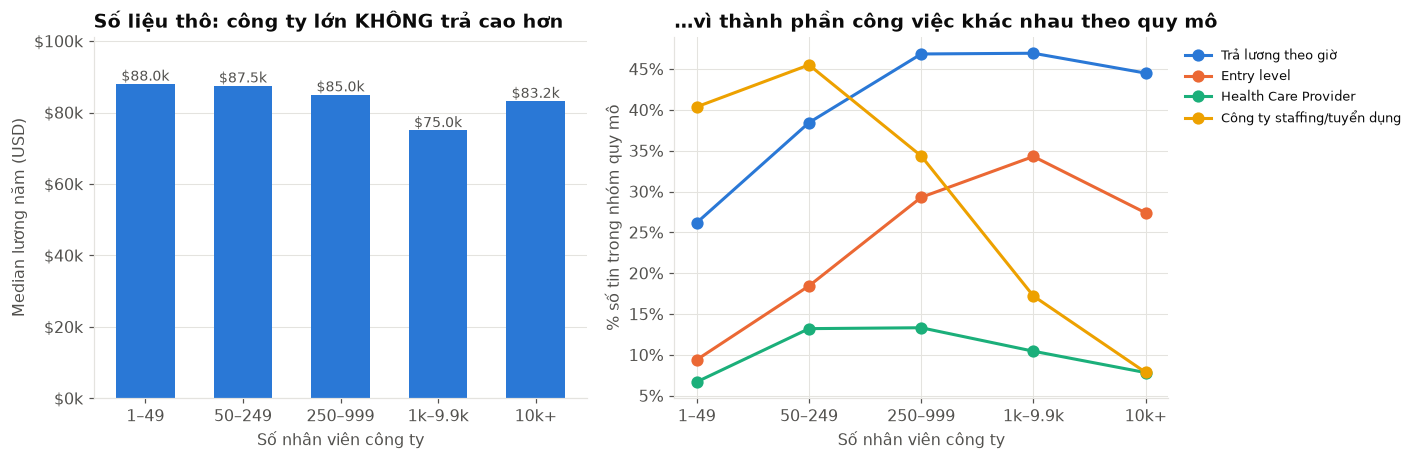

In [30]:
comp4 = pd.DataFrame({
    'Trả lương theo giờ': q4['pay_period_fixed'] == 'HOURLY',
    'Entry level': q4['experience_level'] == 'Entry level',
    'Mid-Senior trở lên': q4['experience_level'].isin(['Mid-Senior level', 'Director', 'Executive']),
    'Health Care Provider': q4['function_abr'] == 'HCPR',
    'Công ty staffing/tuyển dụng': q4['staffing'],
    'Hợp đồng (Contract)': q4['work_type'] == 'Contract',
}).groupby(q4['size']).mean().loc[SIZES]
display((comp4 * 100).round(1))
meds = q4.groupby('size')['annual_salary'].median().loc[SIZES]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={'width_ratios': [1, 1]})
ax = axes[0]
ax.bar(SIZES, meds, color=SERIES[0], width=0.6)
for i, v in enumerate(meds):
    ax.text(i, v, f'${v/1000:.1f}k', ha='center', va='bottom', fontsize=9, color=TEXT_2)
ax.yaxis.set_major_formatter(usd); ax.set_ylim(0, meds.max() * 1.15)
ax.set_xlabel('Số nhân viên công ty'); ax.set_ylabel('Median lương năm (USD)')
ax.set_title('Số liệu thô: công ty lớn KHÔNG trả cao hơn'); ax.grid(axis='x', visible=False)
ax = axes[1]
for k, c in enumerate(['Trả lương theo giờ', 'Entry level', 'Health Care Provider', 'Công ty staffing/tuyển dụng']):
    ax.plot(SIZES, comp4[c], marker='o', color=SERIES[k], label=c)
ax.yaxis.set_major_formatter(pct); ax.set_ylabel('% số tin trong nhóm quy mô')
ax.set_xlabel('Số nhân viên công ty'); ax.set_title('…vì thành phần công việc khác nhau theo quy mô')
ax.legend(fontsize=8.5, loc='upper left', bbox_to_anchor=(1.01, 1.0))
plt.tight_layout(); plt.show()

### Phân tích 2 – Thô vs. công việc tương đương (D4, D5)
So sánh từng nhóm quy mô với công ty 1–49 nhân viên theo hai cách:
1. **Thô:** tỉ số median lương của toàn bộ tin hai nhóm.
2. **Công việc tương đương:** tỉ số median lương **trong từng nhóm con** cấp bậc × chức năng × đơn vị lương (≥ 10 tin mỗi bên), gộp bằng trung bình có trọng số.

CI 95%: bootstrap 200 lần. Nếu dấu của chênh lệch đổi từ cách 1 sang cách 2 thì đó là nghịch lý Simpson.

In [31]:
BY4 = ['experience_level', 'job_function', 'pay_period_fixed']
COLS4 = ['size', 'annual_salary', 'experience_level', 'job_function', 'pay_period_fixed', 'work_type']

def size_gap(d, size, by, min_n=10):
    """% chênh lệch lương của nhóm quy mô `size` so với công ty 1–49 NV, trong từng nhóm con `by`."""
    return compare_within_groups(d, by, 'size', 'annual_salary', size, '1–49', agg='median', min_n=min_n, log_ratio=True)

rows = []
for s in SIZES[1:]:
    for name, by in [('Thô', []), ('Công việc tương đương', BY4)]:
        est, lo, hi = bootstrap_df(q4[COLS4], lambda d: size_gap(d, s, by)[0], n_boot=200)
        rows.append({'quy mô': s, 'cách so sánh': name, 'chênh lệch': est, 'lo': lo, 'hi': hi})
res4 = pd.DataFrame(rows)
display(res4.pivot(index='quy mô', columns='cách so sánh', values='chênh lệch').loc[SIZES[1:]].style.format('{:+.1%}'))
print('Chênh lệch so với công ty 1–49 NV:')
for _, r in res4.iterrows():
    print(f"  {r['quy mô']:>8} – {r['cách so sánh']:<22}: {ci_text(r['chênh lệch'], r['lo'], r['hi'], '%')}")

cách so sánh,Công việc tương đương,Thô
quy mô,,
50–249,-1.1%,-0.6%
250–999,-1.3%,-3.4%
1k–9.9k,-0.7%,-14.8%
10k+,+9.8%,-5.5%


Chênh lệch so với công ty 1–49 NV:
    50–249 – Thô                   : -0.6% (95% CI -3.9% … +2.9%)
    50–249 – Công việc tương đương : -1.1% (95% CI -3.4% … +1.0%)
   250–999 – Thô                   : -3.4% (95% CI -7.6% … -1.2%)
   250–999 – Công việc tương đương : -1.3% (95% CI -4.2% … +1.1%)
   1k–9.9k – Thô                   : -14.8% (95% CI -17.8% … -12.4%)
   1k–9.9k – Công việc tương đương : -0.7% (95% CI -2.6% … +1.6%)
      10k+ – Thô                   : -5.5% (95% CI -8.3% … -2.6%)
      10k+ – Công việc tương đương : +9.8% (95% CI +6.7% … +12.6%)


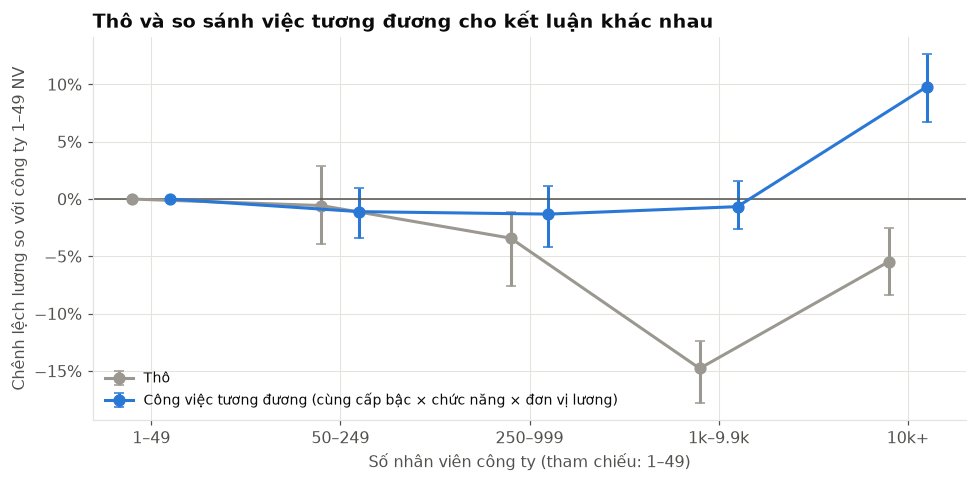

In [32]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(SIZES))
for name, c, off, label in [('Thô', NEUTRAL, -0.1, 'Thô'),
                            ('Công việc tương đương', SERIES[0], 0.1, 'Công việc tương đương (cùng cấp bậc × chức năng × đơn vị lương)')]:
    r = res4[res4['cách so sánh'] == name].set_index('quy mô')[['chênh lệch', 'lo', 'hi']].reindex(SIZES).fillna(0)
    ax.errorbar(x + off, r['chênh lệch'], yerr=[r['chênh lệch'] - r['lo'], r['hi'] - r['chênh lệch']], fmt='o-',
                color=c, capsize=3, label=label)
ax.axhline(0, color=TEXT_2, linewidth=1)
ax.set_xticks(x); ax.set_xticklabels(SIZES)
ax.yaxis.set_major_formatter(pct)
ax.set_xlabel('Số nhân viên công ty (tham chiếu: 1–49)'); ax.set_ylabel('Chênh lệch lương so với công ty 1–49 NV')
ax.set_title('Thô và so sánh việc tương đương cho kết luận khác nhau')
ax.legend(loc='lower left', fontsize=9)
plt.tight_layout(); plt.show()

### Phân tích 3 – Kiểm tra độ vững (D6)
So sánh *10k+ vs. 1–49 nhân viên, công việc tương đương* dưới các lựa chọn khác (CI bootstrap 100 lần):
- **Ngưỡng ≥ 20 tin** mỗi bên trong nhóm con; **thêm loại hợp đồng** vào nhóm con.
- **Bỏ công ty staffing/tuyển dụng**: họ đăng tin hộ khách hàng, nên quy mô của *họ* không phải quy mô nơi làm việc thật.
- **Chỉ YEARLY**, **chỉ Full-time**, **loại bản sao**.
- **Trong từng nhóm chức năng lớn** (IT, Sales, Health Care Provider) – xem hiệu ứng có nhất quán.
- **Dùng mã quy mô `company_size` (0–7) của LinkedIn** thay cho số nhân viên: so sánh mã 7 (lớn nhất) với mã 1–2.

In [33]:
cs = q4[q4['company_size'].notna()].copy()
cs['size'] = np.select([cs['company_size'] <= 2, cs['company_size'] == 7], ['1–49', '10k+'], 'giữa')

alt4 = {
    'Gốc (≥ 10 tin mỗi bên)': (q4, BY4, 10),
    'Ngưỡng ≥ 20 tin mỗi bên': (q4, BY4, 20),
    'Thêm loại hợp đồng vào nhóm con': (q4, BY4 + ['work_type'], 10),
    'Bỏ công ty staffing/tuyển dụng': (q4[~q4['staffing']], BY4, 10),
    'Chỉ YEARLY': (q4[q4['pay_period_fixed'] == 'YEARLY'], BY4, 10),
    'Chỉ Full-time': (q4[q4['work_type'] == 'Full-time'], BY4, 10),
    'Loại bản sao đa địa điểm': (q4.drop_duplicates(['company_name', 'title', 'annual_salary']), BY4, 10),
    'Chỉ Information Technology': (q4[q4['function_abr'] == 'IT'], BY4, 10),
    'Chỉ Sales': (q4[q4['function_abr'] == 'SALE'], BY4, 10),
    'Chỉ Health Care Provider': (q4[q4['function_abr'] == 'HCPR'], BY4, 10),
    'Mã company_size 7 vs 1–2': (cs, BY4, 10),
}
rows = []
for name, (d, by, mn) in alt4.items():
    est, lo, hi = bootstrap_df(d[COLS4], lambda x: size_gap(x, '10k+', by, mn)[0], n_boot=100)
    rows.append({'phương án': name, 'chênh lệch': est, 'lo': lo, 'hi': hi, 'n': len(d),
                 'số nhóm con': len(size_gap(d, '10k+', by, mn)[1])})
rob4 = pd.DataFrame(rows).set_index('phương án')
rob4.style.format({'chênh lệch': '{:+.1%}', 'lo': '{:+.1%}', 'hi': '{:+.1%}', 'n': '{:,}', 'số nhóm con': '{:,}'})

,chênh lệch,lo,hi,n,số nhóm con
phương án,,,,,
Gốc (≥ 10 tin mỗi bên),+9.8%,+7.0%,+12.7%,"35,457",93
Ngưỡng ≥ 20 tin mỗi bên,+11.0%,+7.0%,+14.0%,"35,457",51
Thêm loại hợp đồng vào nhóm con,+14.4%,+10.7%,+16.9%,"35,457",84
Bỏ công ty staffing/tuyển dụng,+19.2%,+14.5%,+23.0%,"26,406",55
Chỉ YEARLY,+18.4%,+15.5%,+22.8%,"19,913",62
Chỉ Full-time,+15.1%,+12.2%,+19.3%,"28,680",79
Loại bản sao đa địa điểm,+10.2%,+7.6%,+13.4%,"32,892",91
Chỉ Information Technology,+0.5%,-6.4%,+10.0%,"2,910",8
Chỉ Sales,+22.3%,+14.0%,+27.7%,"3,154",7


### Kết luận Q4

**Trả lời: Có, nhưng chỉ ở công ty rất lớn – còn số liệu thô thì nói điều ngược lại.**
- **Thô:** median lương giảm từ **$88.0k** (công ty 1–49 NV) xuống **$75.0k** (1k–9.9k NV) và $83.2k (10k+). Công ty 10k+ trả **thấp hơn 5.5%** (95% CI −8.3 … −2.6%) so với công ty 1–49 NV; công ty 1k–9.9k thấp hơn 14.8%.
- **Nguyên nhân:** công ty lớn tuyển nhiều việc lương thấp hơn. Tỉ lệ tin trả theo giờ là 26% ở công ty nhỏ so với 44–47% ở công ty từ 250 nhân viên trở lên; tỉ lệ Entry level là 9% so với 27–34%. Ngoài ra, 40% tin của "công ty nhỏ" đến từ **công ty staffing/tuyển dụng** đăng hộ khách hàng.
- **So sánh công việc tương đương** (cùng cấp bậc × chức năng × đơn vị lương): công ty **10k+ trả cao hơn 9.8%** (95% CI +6.7 … +12.6%) so với công ty 1–49 NV. Các nhóm quy mô ở giữa không khác công ty nhỏ (CI đều chứa 0) – riêng nhóm 1k–9.9k đổi từ −14.8% về −0.7%. Dấu của chênh lệch ở nhóm 10k+ **đảo từ âm sang dương**: đây là **nghịch lý Simpson**.

**Độ vững (D6).** Mức chênh của nhóm 10k+ luôn dương: +9.8% (gốc), +11.0% (ngưỡng 20 tin), +10.2% (loại bản sao), +14.4% (thêm loại hợp đồng vào nhóm con), +15.1% (chỉ Full-time), +18.4% (chỉ YEARLY) và **+19.2%** (bỏ công ty staffing – vì quy mô của họ không phải quy mô nơi làm việc thật). Khi dùng mã quy mô `company_size` của LinkedIn (7 vs 1–2), mức chênh nhỏ hơn nhiều: +2.9% (CI +1.4 … +5.6%). **Hiệu ứng không đồng đều giữa các nghề:** Sales +22.3% (CI +14.0 … +27.7%), **IT gần như không có chênh lệch** (+0.5%, CI −6.4 … +10.0%), còn ở Health Care Provider công ty lớn lại trả **thấp hơn** 22.2% (CI −35.1 … −5.4%), dù kết quả này chỉ dựa trên 5 nhóm con.

**Ý nghĩa thực tế.** "Công ty lớn trả cao hơn" là đúng nhưng chỉ với tập đoàn ≥ 10,000 nhân viên, và độ lớn phụ thuộc cách đo: khoảng **10–19%** theo số nhân viên, chỉ ~3% theo mã quy mô của LinkedIn. Riêng **ngành IT, công ty nhỏ công bố lương ngang công ty lớn**, nên sinh viên IT không cần mặc định ưu tiên tập đoàn vì lương cơ bản. Với người phân tích dữ liệu, đây là ví dụ điển hình cho thấy so sánh thô có thể cho kết luận **ngược dấu**.

**Hạn chế.** (1) Số nhân viên là của toàn công ty (toàn cầu), không phải chi nhánh tuyển dụng. (2) Chỉ có lương cơ bản công bố; công ty lớn thường có thêm thưởng, cổ phiếu. (3) Hai cách đo quy mô cho độ lớn khác nhau (+9.8% so với +2.9%): kết luận về *dấu* là vững, nhưng *độ lớn* thì chưa chắc chắn. (4) Nhóm con chưa gồm bang và remote, vì thêm biến nữa thì nhóm con quá nhỏ.

---
## Q5 – Yếu tố nào khiến người xem tin nộp đơn nhiều hơn?
*Người phụ trách: Hoàng Hùng Quân (23120338)*

**Câu hỏi.** Trong các tin có ≥ 10 lượt xem, hai yếu tố nhà tuyển dụng tự quyết định được – **cho phép remote** và **công khai lương** – gắn với tỉ lệ ứng tuyển trên lượt xem (`applies / views`) cao hơn bao nhiêu điểm phần trăm, khi so sánh trong cùng hình thức nộp đơn, cấp bậc và nhóm chức năng? Kết luận có đổi khi thay ngưỡng lượt xem hoặc cách xử lý `applies` bị thiếu không?

**Động lực.** Nhà tuyển dụng muốn tin đăng thu hút được nhiều ứng viên. Biết yếu tố nào hiệu quả hơn (mở remote hay ghi lương) giúp ưu tiên thay đổi. Người tìm việc cũng thấy được mức độ cạnh tranh của từng loại tin.

### Tiền xử lý
1. Chỉ giữ tin có `views` (bỏ 1.4% thiếu) và bỏ 1 tin `UnknownApply`.
2. `applies` thiếu → **0** (notebook 01: `applies` không bao giờ bằng 0 và tin thiếu `applies` có rất ít lượt xem). Robustness: bỏ các tin này thay vì điền 0.
3. Biến dẫn xuất (D3): `conv = applies_filled / views` – **tỉ lệ chuyển đổi**. Dùng tỉ lệ thay cho số lượt ứng tuyển vì `applies` phụ thuộc mạnh vào việc tin đã đăng bao lâu và được hiển thị bao nhiêu (không đo được); chia cho `views` triệt tiêu phần lớn yếu tố này.
4. Chỉ giữ tin có **≥ 10 lượt xem**: với 1–2 lượt xem, `conv` chỉ nhận vài giá trị (0, 0.5, 1) và rất nhiễu. Robustness: ngưỡng 1, 5, 20, 50.
5. **So sánh trong cùng `application_type`:** với `OffsiteApply` (nộp trên web công ty), LinkedIn chỉ ghi nhận được lượt bấm "Apply", khác bản chất với nộp đơn ngay trên LinkedIn – nên luôn đưa hình thức nộp đơn vào làm biến kiểm soát/phân tầng.

In [34]:
steps = [('Bảng đã làm sạch', len(df))]
q5 = df[df['views'].notna()]
steps.append(('Có views', len(q5)))
q5 = q5[q5['application_type'] != 'UnknownApply'].copy()
steps.append(('Bỏ UnknownApply', len(q5)))
q5['conv'] = q5['applies_filled'] / q5['views']
q5['disclosed'] = q5['salary_disclosed'].astype(int)
q5_all = q5.copy()
q5 = q5[q5['views'] >= 10].copy()
steps.append(('views ≥ 10', len(q5)))
display(row_report(steps))
APP = {'OffsiteApply': 'Nộp trên web công ty', 'ComplexOnsiteApply': 'LinkedIn – có câu hỏi sàng lọc', 'SimpleOnsiteApply': 'LinkedIn – Easy Apply đơn giản'}
q5['app'] = q5['application_type'].map(APP)
print(q5.groupby('app')['conv'].describe(percentiles=[.5])[['count', 'mean', '50%']])

,bước,số dòng,thay đổi
0,Bảng đã làm sạch,123849,0
1,Có views,122160,-1689
2,Bỏ UnknownApply,122159,-1
3,views ≥ 10,24755,-97404


                                    count  mean   50%
app                                                  
LinkedIn – Easy Apply đơn giản  2,010.000 0.138 0.100
LinkedIn – có câu hỏi sàng lọc 11,545.000 0.164 0.143
Nộp trên web công ty           11,200.000 0.090 0.075


### Phân tích 1 – Tỉ lệ chuyển đổi thô theo từng yếu tố, trong từng hình thức nộp đơn

nhóm,Có ghi lương,Không ghi lương,Không remote,Remote
hình thức,,,,
LinkedIn – Easy Apply đơn giản,15.8%,12.9%,12.2%,18.5%
LinkedIn – có câu hỏi sàng lọc,16.5%,16.4%,14.5%,21.7%
Nộp trên web công ty,9.7%,8.6%,7.9%,12.5%


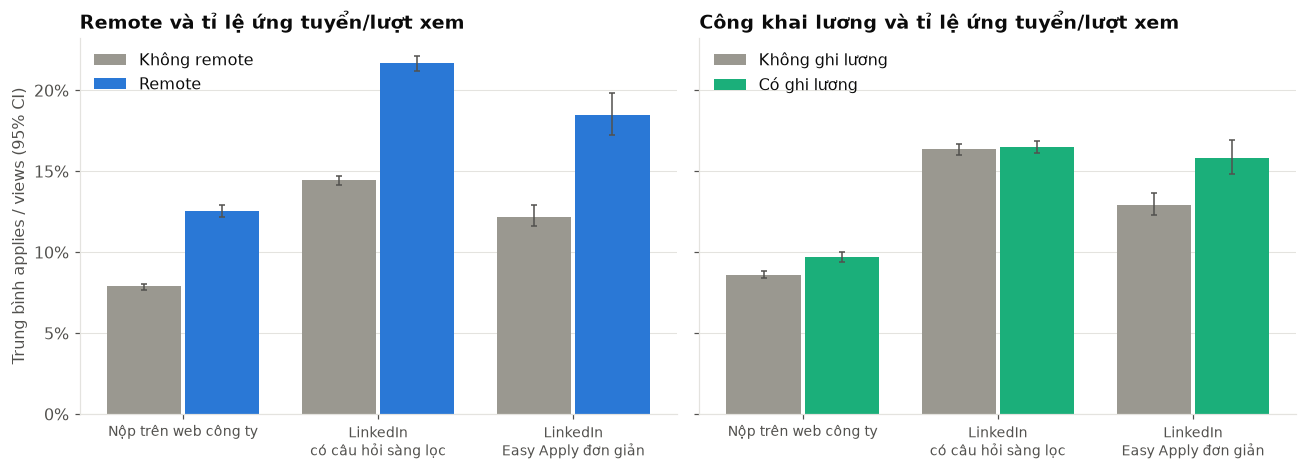

In [35]:
tab5 = []
for lever, lab1, lab0 in [('remote_allowed', 'Remote', 'Không remote'), ('disclosed', 'Có ghi lương', 'Không ghi lương')]:
    for app, g in q5.groupby('app'):
        for v, lab in [(1, lab1), (0, lab0)]:
            s = g.loc[g[lever] == v, 'conv']
            est, lo, hi = bootstrap_ci(s.to_numpy(), stat=np.mean, n_boot=500)
            tab5.append({'yếu tố': lever, 'nhóm': lab, 'hình thức': app, 'conv': est, 'lo': lo, 'hi': hi, 'n': len(s)})
tab5 = pd.DataFrame(tab5)
display(tab5.pivot_table(index=['hình thức'], columns='nhóm', values='conv').style.format('{:.1%}'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
apps = list(APP.values())
for ax, (lever, l1, l0, c1) in zip(axes, [('remote_allowed', 'Remote', 'Không remote', SERIES[0]),
                                            ('disclosed', 'Có ghi lương', 'Không ghi lương', SERIES[2])]):
    x = np.arange(len(apps)); w = 0.38
    for off, lab, c in [(-w/2 - 0.01, l0, NEUTRAL), (w/2 + 0.01, l1, c1)]:
        sub = tab5[(tab5['yếu tố'] == lever) & (tab5['nhóm'] == lab)].set_index('hình thức').loc[apps]
        ax.bar(x + off, sub['conv'], width=w, color=c, label=lab)
        ax.errorbar(x + off, sub['conv'], yerr=[sub['conv'] - sub['lo'], sub['hi'] - sub['conv']], fmt='none', ecolor=TEXT_2, capsize=2, linewidth=1)
    ax.set_xticks(x); ax.set_xticklabels([a.replace(' – ', '\n') for a in apps], fontsize=9)
    ax.yaxis.set_major_formatter(pct); ax.legend(loc='upper left'); ax.grid(axis='x', visible=False)
    ax.set_title(f"{'Remote' if lever == 'remote_allowed' else 'Công khai lương'} và tỉ lệ ứng tuyển/lượt xem")
axes[0].set_ylabel('Trung bình applies / views (95% CI)')
plt.tight_layout(); plt.show()

### Phân tích 2 – So sánh trong cùng nhóm con (D4, D5)
So sánh tin có / không có yếu tố (remote; ghi lương) **trong từng nhóm con**, thêm dần biến kiểm soát: cùng hình thức nộp đơn → cùng hình thức × cấp bậc × chức năng → thêm **nhóm lượt xem** (4 nhóm theo phân vị của `views`), vì tin được xem nhiều có thể có nhiều người chỉ "lướt qua". Chỉ giữ nhóm con có ≥ 10 tin mỗi bên. Kết quả là chênh lệch **điểm phần trăm** của tỉ lệ applies/views. CI: bootstrap 200 lần.

In [36]:
q5['views_bin'] = pd.qcut(q5['views'], 4, duplicates='drop').astype(str)
COLS5 = ['remote_allowed', 'disclosed', 'conv', 'application_type', 'experience_level', 'job_function', 'views_bin']

def lever_gap(d, lever, by, min_n=10):
    """Chênh lệch tỉ lệ applies/views giữa tin có (1) và không có (0) yếu tố `lever`, trong từng nhóm con."""
    return compare_within_groups(d, by, lever, 'conv', 1, 0, agg='mean', min_n=min_n)

steps5 = {
    'Thô (không kiểm soát)': [],
    'Cùng hình thức nộp đơn': ['application_type'],
    'Cùng hình thức × cấp bậc × chức năng': ['application_type', 'experience_level', 'job_function'],
    '+ cùng nhóm lượt xem': ['application_type', 'experience_level', 'job_function', 'views_bin'],
}
rows = []
for lever, lab in [('remote_allowed', 'Remote'), ('disclosed', 'Ghi lương')]:
    for name, by in steps5.items():
        est, lo, hi = bootstrap_df(q5[COLS5], lambda d: lever_gap(d, lever, by)[0], n_boot=200)
        tab = lever_gap(q5, lever, by)[1]
        rows.append({'yếu tố': lab, 'cách so sánh': name, 'chênh lệch': est, 'lo': lo, 'hi': hi,
                     'số nhóm con': len(tab), '% nhóm con có chênh lệch dương': (tab['chenh_lech'] > 0).mean()})
eff5 = pd.DataFrame(rows)
base_rate = q5['conv'].mean()
print(f'Tỉ lệ applies/views trung bình: {base_rate:.1%}')
eff5.style.format({'chênh lệch': '{:+.2%}', 'lo': '{:+.2%}', 'hi': '{:+.2%}', '% nhóm con có chênh lệch dương': '{:.0%}'})

Tỉ lệ applies/views trung bình: 12.8%


,yếu tố,cách so sánh,chênh lệch,lo,hi,số nhóm con,% nhóm con có chênh lệch dương
0,Remote,Thô (không kiểm soát),+6.39%,+6.01%,+6.77%,1,100%
1,Remote,Cùng hình thức nộp đơn,+6.08%,+5.72%,+6.46%,3,100%
2,Remote,Cùng hình thức × cấp bậc × chức năng,+5.68%,+5.29%,+6.14%,132,98%
3,Remote,+ cùng nhóm lượt xem,+3.28%,+2.76%,+3.82%,144,83%
4,Ghi lương,Thô (không kiểm soát),+1.38%,+1.11%,+1.68%,1,100%
5,Ghi lương,Cùng hình thức nộp đơn,+0.70%,+0.38%,+0.99%,3,100%
6,Ghi lương,Cùng hình thức × cấp bậc × chức năng,+1.03%,+0.72%,+1.32%,176,68%
7,Ghi lương,+ cùng nhóm lượt xem,+0.67%,+0.34%,+1.00%,228,58%


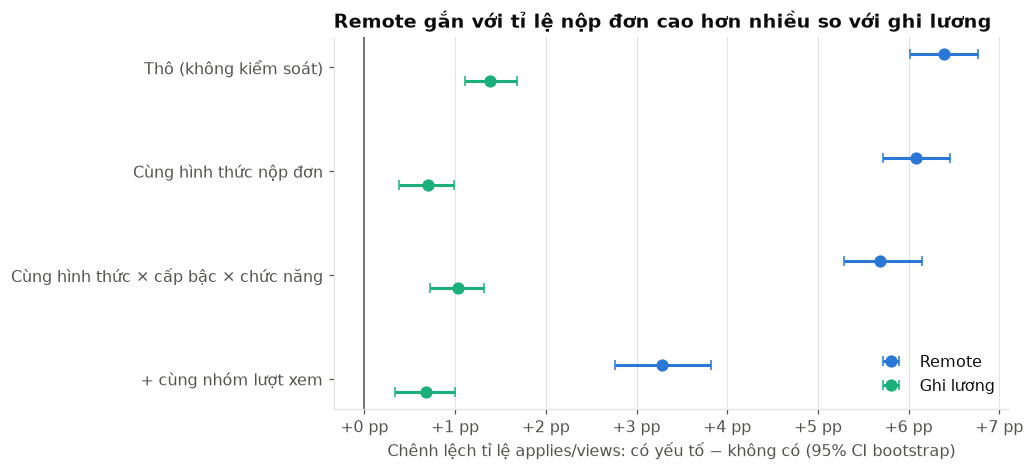

In [37]:
fig, ax = plt.subplots(figsize=(9.5, 4.4))
names5 = list(steps5)
for lab, c, off in [('Remote', SERIES[0], -0.13), ('Ghi lương', SERIES[2], 0.13)]:
    s = eff5[eff5['yếu tố'] == lab].set_index('cách so sánh').loc[names5]
    yy = np.arange(len(names5)) + off
    ax.errorbar(s['chênh lệch'], yy, xerr=[s['chênh lệch'] - s['lo'], s['hi'] - s['chênh lệch']], fmt='o',
                color=c, capsize=3, label=lab)
ax.axvline(0, color=TEXT_2, linewidth=1)
ax.set_yticks(range(len(names5))); ax.set_yticklabels(names5); ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v*100:+.0f} pp'))
ax.set_xlabel('Chênh lệch tỉ lệ applies/views: có yếu tố − không có (95% CI bootstrap)')
ax.set_title('Remote gắn với tỉ lệ nộp đơn cao hơn nhiều so với ghi lương')
ax.legend(loc='lower right'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

### Phân tích 3 – Kiểm tra độ vững (D6)

,yếu tố,remote_allowed,disclosed
phương án,n,,
views ≥ 1,122159,+4.41%,+0.74%
views ≥ 5,57872,+5.55%,+1.07%
views ≥ 10,24755,+5.68%,+1.03%
views ≥ 20,14129,+4.72%,+0.68%
views ≥ 50,5923,+3.34%,+0.57%
Bỏ tin thiếu applies (thay vì điền 0),18826,+4.24%,+0.46%
Chỉ nộp đơn trên LinkedIn,13555,+6.59%,+0.96%


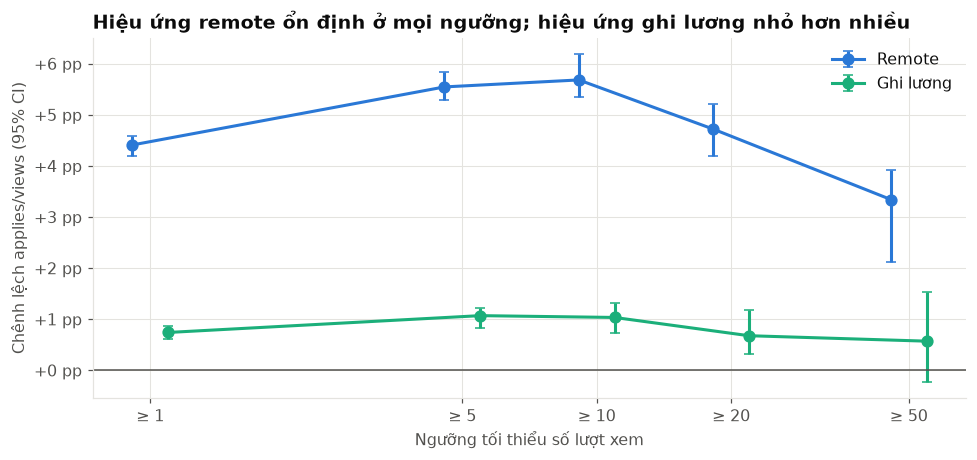

In [38]:
BY5 = steps5['Cùng hình thức × cấp bậc × chức năng']
COLS5b = ['remote_allowed', 'disclosed', 'conv', 'application_type', 'experience_level', 'job_function']
variants5 = {f'views ≥ {mv}': (q5_all[q5_all['views'] >= mv], mv) for mv in [1, 5, 10, 20, 50]}
variants5['Bỏ tin thiếu applies (thay vì điền 0)'] = (q5_all[(q5_all['views'] >= 10) & q5_all['applies'].notna()], np.nan)
variants5['Chỉ nộp đơn trên LinkedIn'] = (q5[q5['application_type'] != 'OffsiteApply'], np.nan)
rows = []
for name, (d, mv) in variants5.items():
    for lever in ['remote_allowed', 'disclosed']:
        est, lo, hi = bootstrap_df(d[COLS5b], lambda x: lever_gap(x, lever, BY5)[0], n_boot=100)
        rows.append({'phương án': name, 'mv': mv, 'yếu tố': lever, 'chênh lệch': est, 'lo': lo, 'hi': hi, 'n': len(d)})
rob5 = pd.DataFrame(rows)
display(rob5.pivot_table(index=['phương án', 'n'], columns='yếu tố', values='chênh lệch', sort=False).style.format('{:+.2%}'))

fig, ax = plt.subplots(figsize=(9, 4.3))
for lv, lab, c, off in [('remote_allowed', 'Remote', SERIES[0], -0.04), ('disclosed', 'Ghi lương', SERIES[2], 0.04)]:
    s = rob5[(rob5['yếu tố'] == lv) & rob5['mv'].notna()]
    xs = np.log10(s['mv'].astype(float)) + off
    ax.errorbar(xs, s['chênh lệch'], yerr=[s['chênh lệch'] - s['lo'], s['hi'] - s['chênh lệch']], fmt='o-', color=c,
                capsize=3, label=lab)
ax.axhline(0, color=TEXT_2, linewidth=1)
ax.set_xticks(np.log10([1, 5, 10, 20, 50])); ax.set_xticklabels(['≥ 1', '≥ 5', '≥ 10', '≥ 20', '≥ 50'])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v*100:+.0f} pp'))
ax.set_xlabel('Ngưỡng tối thiểu số lượt xem'); ax.set_ylabel('Chênh lệch applies/views (95% CI)')
ax.set_title('Hiệu ứng remote ổn định ở mọi ngưỡng; hiệu ứng ghi lương nhỏ hơn nhiều')
ax.legend()
plt.tight_layout(); plt.show()

### Kết luận Q5

**Trả lời.** Trong 24,755 tin có ≥ 10 lượt xem, trung bình **12.8%** người xem nộp đơn (hoặc bấm nộp đơn). So sánh trong cùng hình thức nộp đơn × cấp bậc × nhóm chức năng:
- **Cho phép remote: +5.7 điểm %** (95% CI +5.3 … +6.1), tức cao hơn khoảng **44%** so với mức trung bình. Trong 98% của 132 nhóm con, tin remote có tỉ lệ cao hơn.
- **Công khai lương: +1.0 điểm %** (CI +0.7 … +1.3), tức cao hơn khoảng **8%**. Chỉ 68% của 176 nhóm con có chênh lệch dương.
- Khi so sánh thêm trong cùng nhóm lượt xem (độ phổ biến của tin), cả hai hiệu ứng nhỏ lại (remote +3.3, lương +0.7 điểm %) nhưng CI vẫn không chứa 0.

**Độ vững (D6).** Với các ngưỡng lượt xem 1/5/10/20/50, khi bỏ tin thiếu `applies` thay vì điền 0, hay khi chỉ xét nộp đơn trên LinkedIn, hiệu ứng remote luôn nằm trong **+3.3 đến +6.6 điểm %**, còn hiệu ứng ghi lương trong **+0.5 đến +1.1 điểm %**. **Thứ tự không đổi: remote mạnh gấp khoảng 5–9 lần công khai lương.**

**Ý nghĩa thực tế.** Nếu nhà tuyển dụng muốn tin đăng thu hút nhiều người nộp đơn hơn trên mỗi lượt xem, **mở remote** gắn với mức tăng lớn hơn nhiều so với việc thêm mức lương. Điều này không có nghĩa là công khai lương vô ích: công khai lương có thể khiến những người thấy lương không phù hợp *không nộp* (tự sàng lọc), giúp tiết kiệm thời gian cho cả hai bên – một lợi ích mà tỉ lệ applies/views không đo được.

**Hạn chế.** (1) Đây là quan hệ quan sát, chưa phải nhân quả: tin remote hiển thị cho ứng viên toàn quốc nên tự nhiên có nhiều người đủ điều kiện hơn. (2) Với `OffsiteApply`, LinkedIn chỉ đếm lượt bấm "Apply", không phải đơn thật – nhóm luôn so sánh trong cùng hình thức nộp đơn để tránh trộn hai thước đo. (3) `views`/`applies` là số tích luỹ tại thời điểm cào, không biết tin đã đăng bao lâu. (4) Không đo được *chất lượng* ứng viên.

---
**Tổng kết các câu non-ML và phần phản tư (mục 3.5)** nằm ở cuối notebook 03.